# Étude de cas 3 : Télésurveillance cardiaque (CardioPatch)
## Jalon 4 : *Le rythme est une séquence* (chapitre 4 : RNN, LSTM et GRU)

**M2 SDIA – Advanced Artificial Intelligence – ENSET – 2026-2027**  
Fichier à nommer `Groupe10_UC3_Jalon4.ipynb`.

| Groupe | Membres | Date d'exécution |
|---|---|---|
| `10` | *AAARROUB Wijdane, AIT EL MAHJOUB Abdessamad, TOKO Rayane* | 26/10/2026 |

**Déclaration des sources et de l'usage d'assistants IA** *(exigée par les consignes)* : la structure de ce notebook et le code ont été rédigés avec l'aide d'un assistant IA (Claude, Anthropic) à partir de la fiche du jalon, des consignes et du code de démarrage `uc3_jalon4_depart.py`. Tous les chiffres affichés proviennent de l'exécution du notebook par le groupe. L'analyse des résultats (§ 6, 9.3 et 11) a été rédigée avec l'assistant à partir des sorties exécutées du notebook. *Le groupe doit relire, comprendre et adapter le code et les textes avant la soutenance.*

## 1. Contexte et objectif

**Problème.** *CardioPatch* (entreprise fictive) surveille à domicile des patients sortis de cardiologie. Le système analyse l'ECG par **fenêtres de 10 s** (1 250 points à 125 Hz, en mV) et doit reconnaître **cinq rythmes** :

| Classe | Rythme |
|---|---|
| 0 | rythme sinusal (parfois avec une extrasystole isolée) |
| 1 | fibrillation atriale (FA) |
| 2 | extrasystoles ventriculaires fréquentes |
| 3 | tachycardie sinusale |
| 4 | bloc auriculo-ventriculaire du 2ᵉ degré |

**Objectif du jalon.** Traiter la fenêtre comme une **séquence** :
1. RNN simple puis LSTM sur le signal brut (1 250 pas) ; observation de l'apprentissage et des **normes de gradient** ;
2. modèle **hybride CNN → récurrent** (LSTM ou GRU), comparé au CNN seul ;
3. représentation en **suite de battements** (≤ 40 × [intervalle RR, amplitude QRS]) avec **GRU + masquage** ;
4. comparaison du **coût d'entraînement** (temps/époque, paramètres) et conclusion pour l'**embarqué**.

**Entrées / sorties.** Entrée : fenêtre `(1250, 1)` normalisée, ou suite `(40, 2)`. Sortie : probabilités des 5 classes.

**Critères de réussite (cahier des charges, système *final*, non exigés à la fin du jalon)** : F1 macro ≥ 0,97 ; sensibilité FA à spécificité 95 % ≥ 0,95 ; taille ≤ 2 Mo ; latence ≤ 100 ms par fenêtre. On se mesure à ces cibles et on **explique l'écart**.

**Protocole (imposé).** Découpage **par patient** (280 / 60 / 60) ; tous les réglages sur la **validation** ; le **test n'est utilisé qu'une seule fois**, à la fin, pour le modèle retenu.

> Les fichiers `uc3_patchB.npz` et `uc3_inedits.npz` (domaine patch, signaux inédits) ne servent pas dans ce jalon (ils concernent le jalon 3 et la synthèse finale).

## 2. Environnement et reproductibilité

In [ ]:
import os, sys, time, platform, warnings, importlib.metadata as imd
os.environ.setdefault("KERAS_BACKEND", "tensorflow")   # le code de démarrage utilise tf.GradientTape

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers
import sklearn
from sklearn.metrics import f1_score, confusion_matrix, roc_curve
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")

# ---------------- Réglages globaux ----------------
SEED = 42                 # graine unique du notebook (python, numpy, backend)
MODE_RAPIDE = False       # True = test de fumée (1 époque, 1000 fenêtres) ; False = exécution complète
STABILITE = True          # répéter 3 graines pour les deux meilleurs modèles « bon marché »
keras.utils.set_random_seed(SEED)

print("Python      :", sys.version.split()[0], "|", platform.platform())
print("NumPy       :", np.__version__, "| pandas :", pd.__version__, "| scikit-learn :", sklearn.__version__)
print("TensorFlow  :", tf.__version__, "| Keras :", keras.__version__, "| backend :", keras.backend.backend())
gpus = tf.config.list_physical_devices("GPU")
print("GPU         :", [g.name for g in gpus] if gpus else "aucun (CPU : l'entraînement des RNN sur 1250 pas sera lent)")
print("CPU         :", platform.processor() or platform.machine(), "| cœurs :", os.cpu_count())
print("Graine      :", SEED, "| MODE_RAPIDE :", MODE_RAPIDE)

Python      : 3.13.16 | Linux-6.6.122+-x86_64-with-glibc2.39
NumPy       : 2.1.3 | pandas : 2.2.3 | scikit-learn : 1.6.1
TensorFlow  : 2.21.0 | Keras : 3.13.2 | backend : tensorflow
GPU         : ['/physical_device:GPU:0']
CPU         : x86_64 | cœurs : 2
Graine      : 42 | MODE_RAPIDE : False


**Matériel et contraintes (mesurés).** Google Colab, **GPU NVIDIA T4**, 2 cœurs CPU, Python 3.13.16, TensorFlow 2.21.0 / Keras 3.13.2 (backend TensorFlow), NumPy 2.1.3, scikit-learn 1.6.1. Graine 42 pour Python, NumPy et Keras ; sur GPU, certaines opérations cuDNN restent non déterministes au dernier chiffre près, d'où la répétition sur 3 graines (§ 9.2). Durée : les entraînements du journal s'étendent de 11:08:54 à 11:23:18, soit **≈ 15 minutes** au total (essais, ablation et stabilité compris). Contraintes rencontrées : le `SimpleRNN` n'a pas de noyau cuDNN et déroule 1 250 pas, ce qui le rend lent (8,1 s/époque, 3,1 s par fenêtre en inférence unitaire) ; les mesures de latence portent sur le GPU Colab, pas sur une cible embarquée.

## 3. Données et préparation

Le notebook de démarrage (`uc3_demarrage.ipynb`) fournit `A` (dictionnaire du fichier `uc3_holterA.npz`), `FS`, `detecter_qrs`, le MLP de référence, les métriques et `journaliser`.
Si ce notebook a été exécuté **avant** celui-ci, ses objets sont réutilisés ; sinon, la cellule suivante charge les données et définit des **versions de remplacement** (clairement signalées).

In [3]:
CLASSES = ["Sinusal", "FA", "Extrasyst. V", "Tachy sinus.", "Bloc AV 2"]
NC = len(CLASSES)

def trouver(nom):
    for d in ["/content/data", "data", "./", "/content", "../data", "/mnt/user-data/uploads"]:
        p = os.path.join(d, nom)
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"{nom} introuvable : placer le fichier dans /content/data/")

if "A" not in globals():
    A = dict(np.load(trouver("uc3_holterA.npz")))
    print("A chargé depuis", trouver("uc3_holterA.npz"))
else:
    print("A : réutilisé depuis le notebook de démarrage")

if "FS" not in globals():
    FS = 125

if "detecter_qrs" not in globals():
    from scipy.signal import find_peaks
    def detecter_qrs(x, fs=FS):
        # Version de REMPLACEMENT (détecteur type Pan-Tompkins simplifié) :
        # énergie de la dérivée lissée -> pics -> raffinement sur le max de |x| local.
        x = np.asarray(x, dtype="float32")
        z = x - np.median(x)
        d = np.diff(z, prepend=z[0])
        w = max(1, int(0.08 * fs))
        e = np.convolve(d ** 2, np.ones(w) / w, mode="same")
        p, _ = find_peaks(e, height=0.3 * np.percentile(e, 99), distance=int(0.25 * fs))
        r = int(0.06 * fs)
        pics = [max(0, i - r) + int(np.argmax(np.abs(z[max(0, i - r):i + r + 1]))) for i in p]
        return np.unique(pics).astype(int), e
    print("detecter_qrs : version de remplacement (notebook de démarrage non exécuté)")
else:
    print("detecter_qrs : réutilisé depuis le notebook de démarrage")

# --- Vérifications d'intégrité : dimensions et découpage PAR PATIENT ---
for s in ["train", "val", "test"]:
    print(f"{s:5s} X={A['X_'+s].shape}  fenêtres/patient={np.unique(np.bincount(A['patient_'+s])[np.unique(A['patient_'+s])])}"
          f"  patients={len(np.unique(A['patient_' + s]))}")
P = {s: set(np.unique(A["patient_" + s])) for s in ["train", "val", "test"]}
assert not (P["train"] & P["val"]) and not (P["train"] & P["test"]) and not (P["val"] & P["test"]), "fuite de patients !"
print("OK : aucun patient partagé entre train / val / test")

Y = {s: A["classe_" + s].astype("int32") for s in ["train", "val", "test"]}
dist = pd.DataFrame({s: np.bincount(Y[s], minlength=NC) for s in Y}, index=CLASSES)
dist_pct = (dist / dist.sum() * 100).round(1)
display(pd.concat({"effectifs": dist, "%": dist_pct}, axis=1))

A chargé depuis /content/data/uc3_holterA.npz
detecter_qrs : version de remplacement (notebook de démarrage non exécuté)
train X=(8400, 1250)  fenêtres/patient=[30]  patients=280
val   X=(1800, 1250)  fenêtres/patient=[30]  patients=60
test  X=(1800, 1250)  fenêtres/patient=[30]  patients=60
OK : aucun patient partagé entre train / val / test


effectifs               %            
                 train  val test train   val  test
Sinusal           4348  892  870  51.8  49.6  48.3
FA                1209  238  280  14.4  13.2  15.6
Extrasyst. V      1018  292  205  12.1  16.2  11.4
Tachy sinus.       995  198  152  11.8  11.0   8.4
Bloc AV 2          830  180  293   9.9  10.0  16.3

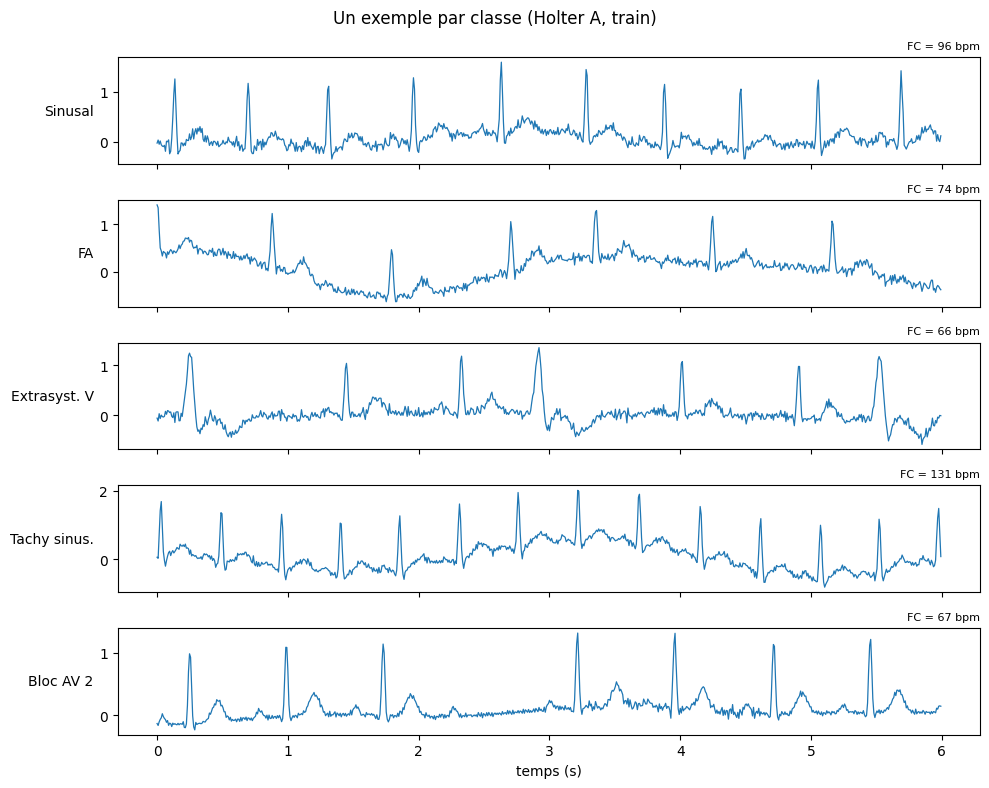

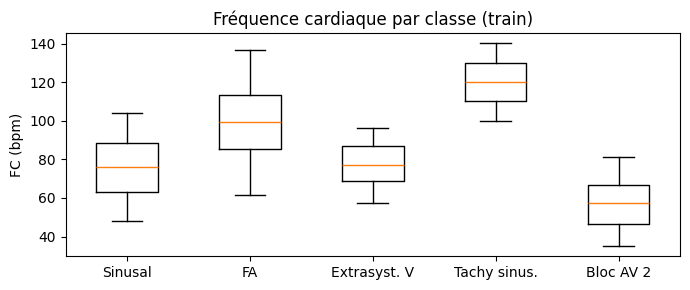

In [4]:
# Exemples de fenêtres (6 premières secondes) et distribution des fréquences cardiaques
fig, ax = plt.subplots(NC, 1, figsize=(10, 8), sharex=True)
t = np.arange(6 * FS) / FS
for c in range(NC):
    i = np.where(A["classe_train"] == c)[0][0]
    ax[c].plot(t, A["X_train"][i, :6 * FS].astype("float32"), lw=0.9)
    ax[c].set_ylabel(CLASSES[c], rotation=0, ha="right", va="center")
    ax[c].set_title(f"FC = {A['fc_train'][i]:.0f} bpm", fontsize=8, loc="right")
ax[-1].set_xlabel("temps (s)")
plt.suptitle("Un exemple par classe (Holter A, train)")
plt.tight_layout(); plt.show()

plt.figure(figsize=(7, 3))
plt.boxplot([A["fc_train"][Y["train"] == c] for c in range(NC)])
plt.xticks(range(1, NC + 1), CLASSES)
plt.ylabel("FC (bpm)"); plt.title("Fréquence cardiaque par classe (train)"); plt.tight_layout(); plt.show()

**Préparation.** Deux représentations d'entrée :

* **Signal brut** `SA` : chaque fenêtre est centrée-réduite *individuellement* (statistiques de la fenêtre elle-même : aucun paramètre n'est ajusté sur d'autres données, donc pas de fuite). Forme `(N, 1250, 1)`.
* **Suite de battements** `BATT` : détection des QRS, puis `(intervalle RR en s, amplitude du QRS en mV)` pour chaque battement, **complétée par des zéros** jusqu'à 40 pas (le masquage `Masking(0.0)` ignorera ce remplissage). La **standardisation de ces deux variables est ajustée sur le train uniquement** (cellule suivante).

Le code ci-dessous est le **code de démarrage fourni** (`uc3_jalon4_depart.py`), sans modification.

In [5]:
# ====== Code de démarrage fourni (uc3_jalon4_depart.py) ======
# Étude de cas 3 - Jalon 4 : code de démarrage
# À exécuter à la suite du notebook de démarrage, exécuté en entier.
import tensorflow as tf

def normaliser_fenetres(X):
    X = X.astype("float32")
    mu, sd = X.mean(axis=1, keepdims=True), X.std(axis=1, keepdims=True)
    return ((X - mu) / (sd + 1e-6))[..., None]

SA = {s: normaliser_fenetres(A["X_" + s]) for s in ["train", "val", "test"]}

# 1. Norme du gradient de chaque variable sur un lot (à suivre au fil de
#    l'entraînement, par exemple entre deux appels fit(epochs=1))
def normes_gradient(model, X, y):
    with tf.GradientTape() as tape:
        p = model(X, training=True)
        perte = keras.ops.mean(
            keras.losses.sparse_categorical_crossentropy(y, p))
    grads = tape.gradient(perte, model.trainable_variables)
    return {v.path: float(tf.norm(g))
            for v, g in zip(model.trainable_variables, grads)}

# 2. Fenêtre -> suite de battements (intervalle RR, amplitude du QRS),
#    complétée par des zéros (à masquer avec layers.Masking)
N_BATT = 40

def suite_battements(x):
    pics, _ = detecter_qrs(x)
    rr = np.diff(pics) / FS
    amp = x[pics[1:]].astype("float32")
    seq = np.zeros((N_BATT, 2), "float32")
    n = min(len(rr), N_BATT)
    seq[:n] = np.column_stack([rr, amp])[:n]
    return seq

BATT = {s: np.stack([suite_battements(x) for x in A["X_" + s]])
        for s in ["train", "val", "test"]}
print(BATT["train"].shape)

(8400, 40, 2)


battements par fenêtre (train) : min/médiane/max = 4 13.0 23 | fenêtres saturées à 40 : 0
fenêtres avec < 3 battements détectés (val) : 0 / 1800


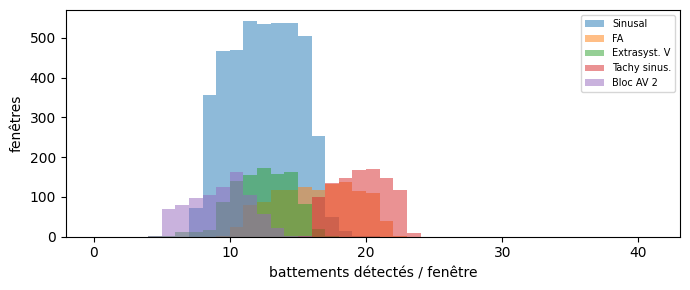

moyenne (RR, amp) = [0.70707184 1.0158277 ] | écart-type = [0.24349633 0.5852286 ]
{'brut': (8400, 1250, 1), 'beats': (8400, 40, 2)}


In [6]:
# --- Contrôle de la représentation « suite de battements » ---
NB = {s: (BATT[s][:, :, 0] > 0).sum(1) for s in BATT}          # nombre de battements réels par fenêtre
print("battements par fenêtre (train) : min/médiane/max =", NB["train"].min(), np.median(NB["train"]), NB["train"].max(),
      "| fenêtres saturées à 40 :", int((NB["train"] >= N_BATT).sum()))
print("fenêtres avec < 3 battements détectés (val) :", int((NB["val"] < 3).sum()), "/", len(NB["val"]))

plt.figure(figsize=(7, 3))
for c in range(NC):
    plt.hist(NB["train"][Y["train"] == c], bins=np.arange(0, 42, 1), alpha=0.5, label=CLASSES[c])
plt.xlabel("battements détectés / fenêtre"); plt.ylabel("fenêtres"); plt.legend(fontsize=7); plt.tight_layout(); plt.show()

# --- Standardisation (ajustée sur le TRAIN, battements réels seulement ; le remplissage reste à 0) ---
M_tr = BATT["train"][:, :, 0] > 0
mu_b, sd_b = BATT["train"][M_tr].mean(0), BATT["train"][M_tr].std(0)
print("moyenne (RR, amp) =", mu_b, "| écart-type =", sd_b)

def norm_batt(B):
    M = B[:, :, 0] > 0
    out = (B - mu_b) / (sd_b + 1e-6)
    out[~M] = 0.0
    return out.astype("float32")

SB = {s: norm_batt(BATT[s]) for s in BATT}
DATA = {"brut": SA, "beats": SB}
print({k: v["train"].shape for k, v in DATA.items()})

## 4. Outils communs : entraînement, métriques, gradients, coût, journal

Tous les modèles sont entraînés **dans les mêmes conditions** (même optimiseur Adam, même taille de lot, écrêtage du gradient `clipnorm=1`, mêmes poids de classes, **sélection de la meilleure époque sur la validation**) pour que la comparaison soit équitable ; seul le nombre d'époques varie (budget documenté plus bas). Le **test n'est jamais touché** dans cette partie.

* **Poids de classes** « équilibrés » (calculés sur le train) : les classes sont déséquilibrées (≈ 52 % de sinusal).
* **Écrêtage du gradient** : stabilise les RNN ; les normes affichées sont mesurées **avant** écrêtage, donc l'observation de la disparition du gradient n'est pas faussée.
* **Critère principal** : F1 macro sur la validation ; critère FA : sensibilité à spécificité 95 % (FA contre le reste).

In [7]:
# ---------- Sous-échantillon de test de fumée ----------
IDX_TR = np.arange(len(Y["train"]))
if MODE_RAPIDE:
    IDX_TR = IDX_TR[:1000]

# ---------- Poids de classes (train) ----------
cnt = np.bincount(Y["train"][IDX_TR], minlength=NC)
CW = {c: float(len(IDX_TR) / (NC * cnt[c])) for c in range(NC)}
print("poids de classes :", {CLASSES[c]: round(w, 2) for c, w in CW.items()})

# ---------- Lot fixe pour suivre les gradients ----------
rng = np.random.default_rng(SEED)
IDX_G = rng.choice(IDX_TR, size=min(256, len(IDX_TR)), replace=False)
XG = {k: DATA[k]["train"][IDX_G] for k in DATA}
YG = Y["train"][IDX_G]

# ---------- Métriques ----------
def sens_a_spec95(y, score_fa):
    """Sensibilité FA (classe 1 vs reste) pour une spécificité >= 95 %. Renvoie (sens, seuil, spec)."""
    yb = (y == 1).astype(int)
    fpr, tpr, thr = roc_curve(yb, score_fa)
    i = np.where(fpr <= 0.05)[0][-1]
    return float(tpr[i]), float(thr[i]), float(1 - fpr[i])

def evaluer(proba, y):
    pred = proba.argmax(1)
    f1c = f1_score(y, pred, average=None, labels=range(NC), zero_division=0)
    cm = confusion_matrix(y, pred, labels=range(NC))
    sens, seuil, spec = sens_a_spec95(y, proba[:, 1])
    return dict(f1_macro=float(f1c.mean()), acc=float((pred == y).mean()), f1_classes=f1c,
                rappel_classes=cm.diagonal() / np.maximum(cm.sum(1), 1), cm=cm,
                sens_fa95=sens, seuil_fa=seuil, spec_fa=spec)

# ---------- Gradient par pas de temps (norme de dL/dx_t) ----------
def grad_par_pas(model, X, y):
    X = tf.convert_to_tensor(X)
    with tf.GradientTape() as tape:
        tape.watch(X)
        p = model(X, training=False)
        perte = keras.ops.mean(keras.losses.sparse_categorical_crossentropy(y, p))
    g = tape.gradient(perte, X).numpy()
    return np.sqrt((g ** 2).sum(-1)).mean(0)          # (T,)

# ---------- Coût : latence ----------
def latence_ms(model, X, n=30):
    xs = [X[i:i + 1] for i in range(n)]
    np.asarray(model(xs[0], training=False))           # échauffement
    t0 = time.perf_counter()
    for x in xs:
        np.asarray(model(x, training=False))
    return (time.perf_counter() - t0) / n * 1e3

def latence_detection_ms(n=30):
    xs = A["X_val"][:n]
    t0 = time.perf_counter()
    for x in xs:
        suite_battements(x)
    return (time.perf_counter() - t0) / n * 1e3

# ---------- Journal d'expériences (jalon=4) ----------
JOURNAL = []
_avert = {"fait": False}
def journal_exp(**kw):
    kw = {"jalon": 4, "horodatage": time.strftime("%Y-%m-%d %H:%M:%S"), **kw}
    JOURNAL.append(kw)
    pd.DataFrame(JOURNAL).to_csv("journal_experiences_jalon4.csv", index=False)
    if "journaliser" in globals():            # fonction du notebook de démarrage (si présente)
        try:
            journaliser(**kw)                 # ADAPTER si la signature du notebook de démarrage diffère
        except Exception as e:
            if not _avert["fait"]:
                print("journaliser() du notebook de démarrage non appelée :", repr(e)[:150], "-> journal local CSV uniquement")
                _avert["fait"] = True

# ---------- Registre des modèles et entraînement ----------
MODELES = {}
os.makedirs("modeles", exist_ok=True)

def entrainer(nom, model, entree, famille, epochs, lr=1e-3, batch=64, patience=None,
              suivre_grad=False, statut="référence", remarque="", seed=SEED,
              registrer=True, sauver=True):
    Xtr, Xva = DATA[entree]["train"][IDX_TR], DATA[entree]["val"]
    ytr, yva = Y["train"][IDX_TR], Y["val"]
    model.compile(optimizer=keras.optimizers.Adam(lr, clipnorm=1.0),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    h = {"perte": [], "perte_val": [], "f1_val": [], "temps": [], "grad": []}
    if suivre_grad:
        h["grad"].append(normes_gradient(model, XG[entree], YG))
        h["gpas_init"] = grad_par_pas(model, XG[entree], YG)
    best, best_w, sans_gain = -1.0, None, 0
    for ep in range(epochs):
        t0 = time.perf_counter()
        r = model.fit(Xtr, ytr, batch_size=batch, epochs=1, shuffle=True, class_weight=CW, verbose=0)
        h["temps"].append(time.perf_counter() - t0)
        p = model.predict(Xva, batch_size=256, verbose=0)
        f1 = f1_score(yva, p.argmax(1), average="macro")
        h["perte"].append(r.history["loss"][0])
        h["perte_val"].append(float(-np.mean(np.log(p[np.arange(len(yva)), yva] + 1e-9))))
        h["f1_val"].append(f1)
        if suivre_grad:
            h["grad"].append(normes_gradient(model, XG[entree], YG))
        print(f"[{nom}] époque {ep+1:2d}/{epochs} | perte {h['perte'][-1]:.3f} | perte val {h['perte_val'][-1]:.3f} "
              f"| F1 macro val {f1:.3f} | {h['temps'][-1]:.1f} s")
        if f1 > best:
            best, best_w, sans_gain = f1, model.get_weights(), 0
        else:
            sans_gain += 1
        if patience and sans_gain >= patience:
            print(f"[{nom}] arrêt anticipé (patience {patience})")
            break
    model.set_weights(best_w)                                    # meilleure époque sur la VALIDATION
    pv = model.predict(Xva, batch_size=256, verbose=0)
    ev = evaluer(pv, yva)
    if suivre_grad:
        h["gpas_fin"] = grad_par_pas(model, XG[entree], YG)
    lat = latence_ms(model, DATA[entree]["val"]) + (latence_detection_ms() if entree == "beats" else 0.0)
    res = dict(nom=nom, famille=famille, entree=entree, model=model, hist=h, val=ev, proba_val=pv,
               params=int(model.count_params()), t_epoque=float(np.median(h["temps"])),
               latence_ms=float(lat), epochs_faites=len(h["temps"]), lr=lr, batch=batch, seed=seed)
    if sauver:
        model.save(f"modeles/{nom.replace(' ', '_').replace('/', '-')}.keras")
        res["taille_fichier_mo"] = os.path.getsize(f"modeles/{nom.replace(' ', '_').replace('/', '-')}.keras") / 2**20
    res["taille_mo_f32"] = res["params"] * 4 / 2**20
    if registrer:
        MODELES[nom] = res
    journal_exp(modele=nom, famille=famille, entree=entree, statut=statut, epochs=len(h["temps"]), lr=lr, batch=batch,
                seed=seed, params=res["params"], t_epoque_s=round(res["t_epoque"], 2), latence_ms=round(res["latence_ms"], 2),
                f1_macro_val=round(ev["f1_macro"], 4), sens_fa95_val=round(ev["sens_fa95"], 4), remarque=remarque)
    print(f"==> {nom} : F1 macro val = {ev['f1_macro']:.3f} | sens FA@spec95 = {ev['sens_fa95']:.3f} | "
          f"{res['params']:,} paramètres | {res['t_epoque']:.1f} s/époque | latence {res['latence_ms']:.1f} ms")
    return res

def courbes(noms, titre=""):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
    for n in noms:
        h = MODELES[n]["hist"]
        ax[0].plot(h["perte_val"], label=n + " (val)"); ax[0].plot(h["perte"], "--", alpha=0.5)
        ax[1].plot(h["f1_val"], label=n)
    ax[0].set_title("perte (trait plein = val, pointillé = train)"); ax[0].set_xlabel("époque")
    ax[1].set_title("F1 macro (validation)"); ax[1].set_xlabel("époque"); ax[1].set_ylim(0, 1)
    ax[0].legend(fontsize=7); ax[1].legend(fontsize=7); plt.suptitle(titre); plt.tight_layout(); plt.show()

poids de classes : {'Sinusal': 0.39, 'FA': 1.39, 'Extrasyst. V': 1.65, 'Tachy sinus.': 1.69, 'Bloc AV 2': 2.02}


**Budget expérimental (documenté).** Optimiseur Adam (pas 10⁻³ sauf essai mentionné), lot 64, écrêtage `clipnorm=1`, une graine (42) pour les comparaisons principales + 3 graines pour la vérification de stabilité (§9), arrêt par patience sur le F1 macro de validation pour les modèles rapides. Nombre d'époques maximal : voir la cellule suivante.

In [8]:
EPOCHS = dict(brut_simple=12, brut_lstm=15, cnn=30, hybride=30, beats=60)
PATIENCE = dict(brut_simple=None, brut_lstm=None, cnn=8, hybride=8, beats=15)   # None = budget fixe (on veut voir toute la courbe)
if MODE_RAPIDE:
    EPOCHS = {k: 1 for k in EPOCHS}
print("budget d'époques :", EPOCHS)

# Noms des modèles (utilisés dans tous les tableaux)
N_SIMPLE, N_LSTM = "RNN simple (brut)", "LSTM (brut)"
N_CNN, N_HGRU, N_HLSTM = "CNN seul", "Hybride CNN+GRU", "Hybride CNN+LSTM"
N_BGRU = "GRU battements (masqué)"

budget d'époques : {'brut_simple': 12, 'brut_lstm': 15, 'cnn': 30, 'hybride': 30, 'beats': 60}


## 5. Vérifications théoriques (à la main, puis vérifiées par le code)

### 5.1 Gradient multiplié par 0,9 (puis 0,99) à chaque pas

Modèle jouet : la contribution d'un pas situé à $k$ pas de la sortie est atténuée par $\lambda^{k}$ (produit des facteurs de Jacobiennes $\partial h_{t}/\partial h_{t-1}$ supposés tous égaux à $\lambda$).

* $0{,}9^{1250}=e^{1250\ln 0{,}9}=e^{-131{,}7}\approx 10^{-57{,}2}\approx 6\times10^{-58}$
* $0{,}99^{1250}=e^{1250\ln 0{,}99}=e^{-12{,}56}\approx 3{,}5\times10^{-6}$

**Implication.** Avec 0,9, le gradient issu du premier pas est **quasi nul** (bien en dessous du plus petit `float32` normal, ≈ 1,2×10⁻³⁸, atteint dès ≈ 830 pas) : le RNN simple ne peut pas apprendre de dépendances sur toute la fenêtre ; sa mémoire effective ne dépasse que quelques dizaines de pas (le gradient est divisé par deux en ≈ 6,6 pas avec 0,9 ; ≈ 69 pas avec 0,99). Or un battement dure environ 50 à 125 pas à 125 Hz et le diagnostic repose sur la **succession** de plusieurs battements (irrégularité des RR en FA, RR longs en bloc AV, extrasystoles prématurées) : un RNN simple sur le signal brut ne peut relier que des événements très proches. Même 0,99 laisse un gradient très faible (10⁻⁶) pour les pas lointains, noyé dans le bruit. Réciproquement, un facteur > 1 produirait l'**explosion** du gradient (d'où l'écrêtage `clipnorm`). Le LSTM/GRU atténue le problème grâce à des **portes** qui permettent un chemin additif (état de cellule) de facteur proche de 1.

### 5.2 Paramètres d'un LSTM à 32 unités, 1 variable par pas (formulation Keras)

Quatre blocs (entrée, oubli, cellule, sortie), chacun avec un noyau d'entrée $(d \times u)$, un noyau récurrent $(u \times u)$ et un biais $(u)$ :

$$P_{LSTM}=4\,\big(u\,(u+d)+u\big)=4\,(32\times 33+32)=4\times 1088=\mathbf{4\,352}$$

(Pour comparaison, GRU Keras avec `reset_after=True` : $3\,(u(u+d)+2u)=3360$.)

In [9]:
# ---- Vérification numérique par le code ----
for lam in (0.9, 0.99):
    print(f"lambda = {lam} : lambda^1250 = {lam**1250:.3e}  (log10 = {1250*np.log10(lam):.1f})"
          f" | pas pour diviser par 2 : {np.log(0.5)/np.log(lam):.1f}"
          f" | pas avant le plus petit float32 normal (1.18e-38) : {np.log(1.1754944e-38)/np.log(lam):.0f}")

u, d = 32, 1
formule_lstm = 4 * (u * (u + d) + u)
formule_gru = 3 * (u * (u + d) + 2 * u)
m_lstm = keras.Sequential([layers.Input((None, d)), layers.LSTM(u)])
m_gru = keras.Sequential([layers.Input((None, d)), layers.GRU(u)])
m_rnn = keras.Sequential([layers.Input((None, d)), layers.SimpleRNN(u)])
print(f"LSTM(32), d=1 : formule = {formule_lstm} | Keras count_params = {m_lstm.count_params()}")
print(f"GRU(32),  d=1 : formule = {formule_gru} | Keras count_params = {m_gru.count_params()}")
print(f"SimpleRNN(32), d=1 : formule u*(u+d)+u = {u*(u+d)+u} | Keras = {m_rnn.count_params()}")
assert m_lstm.count_params() == formule_lstm == 4352 and m_gru.count_params() == formule_gru

lambda = 0.9 : lambda^1250 = 6.355e-58  (log10 = -57.2) | pas pour diviser par 2 : 6.6 | pas avant le plus petit float32 normal (1.18e-38) : 829
lambda = 0.99 : lambda^1250 = 3.499e-06  (log10 = -5.5) | pas pour diviser par 2 : 69.0 | pas avant le plus petit float32 normal (1.18e-38) : 8690
LSTM(32), d=1 : formule = 4352 | Keras count_params = 4352
GRU(32),  d=1 : formule = 3360 | Keras count_params = 3360
SimpleRNN(32), d=1 : formule u*(u+d)+u = 1088 | Keras = 1088


## 6. Expérience 1 : RNN simple puis LSTM sur le signal brut (1 250 pas)

Chaque modèle : une couche récurrente de **32 unités** (dernier état) suivie d'une couche `Dense(5, softmax)`. Pendant l'entraînement on suit, **époque par époque**, la **norme du gradient de chaque variable** (fonction `normes_gradient` fournie) et la **norme du gradient de la perte par rapport à chaque pas de temps d'entrée** (`grad_par_pas`) : cette seconde mesure montre directement *quels pas de la fenêtre influencent la décision*.

In [10]:
def construire_rnn_brut(kind, units=32):
    L = {"simple": layers.SimpleRNN, "lstm": layers.LSTM, "gru": layers.GRU}[kind]
    return keras.Sequential([layers.Input((1250, 1)), L(units), layers.Dense(NC, activation="softmax")], name=f"{kind}_brut")

keras.utils.set_random_seed(SEED)
m = construire_rnn_brut("simple"); m.summary()
R1 = entrainer(N_SIMPLE, m, "brut", "RNN brut", EPOCHS["brut_simple"], suivre_grad=True,
               patience=PATIENCE["brut_simple"], remarque="SimpleRNN(32) sur 1250 pas, référence")

Model: "simple_brut"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_1 (SimpleRNN)        │ (None, 32)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,253 (4.89 KB)

 Trainable params: 1,253 (4.89 KB)

 Non-trainable params: 0 (0.00 B)

[RNN simple (brut)] époque  1/12 | perte 1.620 | perte val 1.594 | F1 macro val 0.200 | 12.7 s
[RNN simple (brut)] époque  2/12 | perte 1.611 | perte val 1.595 | F1 macro val 0.184 | 8.1 s
[RNN simple (brut)] époque  3/12 | perte 1.602 | perte val 1.671 | F1 macro val 0.154 | 8.1 s
[RNN simple (brut)] époque  4/12 | perte 1.607 | perte val 1.622 | F1 macro val 0.186 | 8.9 s
[RNN simple (brut)] époque  5/12 | perte 1.601 | perte val 1.596 | F1 macro val 0.193 | 8.1 s
[RNN simple (brut)] époque  6/12 | perte 1.603 | perte val 1.614 | F1 macro val 0.175 | 8.2 s
[RNN simple (brut)] époque  7/12 | perte 1.594 | perte val 1.586 | F1 macro val 0.166 | 8.2 s
[RNN simple (brut)] époque  8/12 | perte 1.586 | perte val 1.561 | F1 macro val 0.210 | 8.2 s
[RNN simple (brut)] époque  9/12 | perte 1.565 | perte val 1.590 | F1 macro val 0.209 | 10.4 s
[RNN simple (brut)] époque 10/12 | perte 1.576 | perte val 1.724 | F1 macro val 0.124 | 8.1 s
[RNN simple (brut)] époque 11/12 | perte 1.599 | perte val

Model: "lstm_brut"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,517 (17.64 KB)

 Trainable params: 4,517 (17.64 KB)

 Non-trainable params: 0 (0.00 B)

[LSTM (brut)] époque  1/15 | perte 1.606 | perte val 1.591 | F1 macro val 0.200 | 8.7 s
[LSTM (brut)] époque  2/15 | perte 1.584 | perte val 1.553 | F1 macro val 0.208 | 4.4 s
[LSTM (brut)] époque  3/15 | perte 1.514 | perte val 1.533 | F1 macro val 0.168 | 4.5 s
[LSTM (brut)] époque  4/15 | perte 1.440 | perte val 1.520 | F1 macro val 0.217 | 4.5 s
[LSTM (brut)] époque  5/15 | perte 1.389 | perte val 1.383 | F1 macro val 0.341 | 4.5 s
[LSTM (brut)] époque  6/15 | perte 1.387 | perte val 1.411 | F1 macro val 0.335 | 4.5 s
[LSTM (brut)] époque  7/15 | perte 1.372 | perte val 1.318 | F1 macro val 0.351 | 4.5 s
[LSTM (brut)] époque  8/15 | perte 1.194 | perte val 1.372 | F1 macro val 0.350 | 10.2 s
[LSTM (brut)] époque  9/15 | perte 1.195 | perte val 1.360 | F1 macro val 0.403 | 10.5 s
[LSTM (brut)] époque 10/15 | perte 1.277 | perte val 1.267 | F1 macro val 0.441 | 4.5 s
[LSTM (brut)] époque 11/15 | perte 1.214 | perte val 1.219 | F1 macro val 0.478 | 4.5 s
[LSTM (brut)] époque 12/15 | p

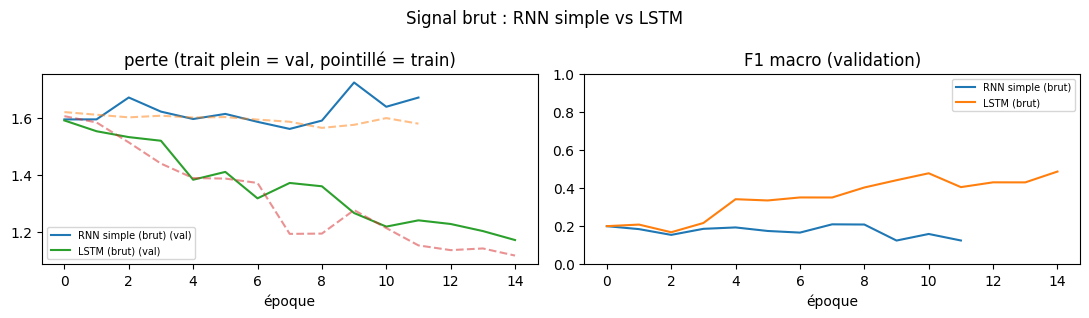

In [11]:
keras.utils.set_random_seed(SEED)
m = construire_rnn_brut("lstm"); m.summary()
R2 = entrainer(N_LSTM, m, "brut", "RNN brut", EPOCHS["brut_lstm"], suivre_grad=True,
               patience=PATIENCE["brut_lstm"], remarque="LSTM(32) sur 1250 pas, référence")
courbes([N_SIMPLE, N_LSTM], "Signal brut : RNN simple vs LSTM")

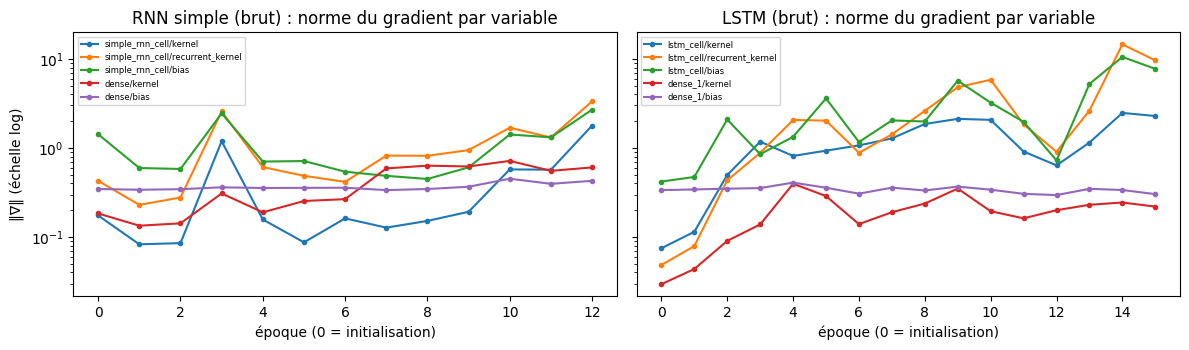

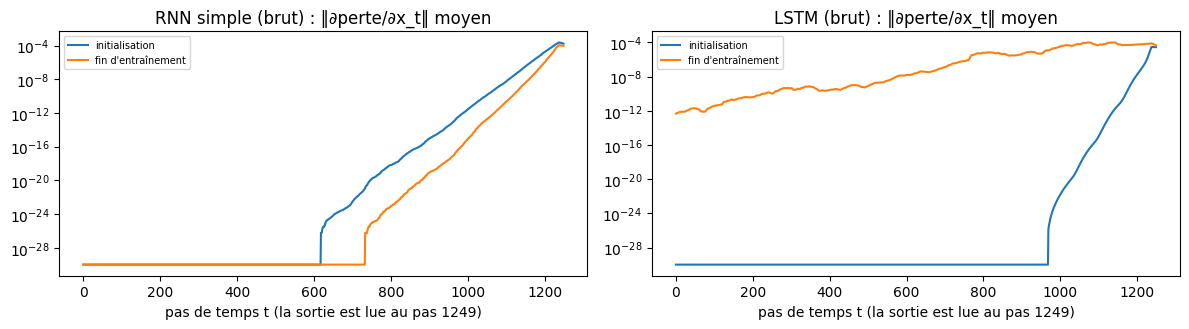

,modèle,moment,‖g‖ pas 0-99,‖g‖ pas 600-649,‖g‖ pas 1150-1249,rapport début/fin
0,RNN simple (brut),init,0.00e+00,1.16e-25,7.07e-05,0.00e+00
1,RNN simple (brut),fin,0.00e+00,0.00e+00,2.84e-05,0.00e+00
2,LSTM (brut),init,0.00e+00,0.00e+00,7.11e-06,0.00e+00
3,LSTM (brut),fin,1.39e-12,2.82e-08,5.86e-05,2.38e-08


In [12]:
# ---- Normes de gradient par variable, au fil des époques ----
def court(path):
    return "/".join(path.split("/")[-2:])

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for a, n in zip(ax, [N_SIMPLE, N_LSTM]):
    G = pd.DataFrame(MODELES[n]["hist"]["grad"]); G.columns = [court(c) for c in G.columns]
    for c in G.columns:
        a.semilogy(G[c].values, marker="o", ms=3, label=c)
    a.set_title(f"{n} : norme du gradient par variable"); a.set_xlabel("époque (0 = initialisation)"); a.legend(fontsize=6)
ax[0].set_ylabel("‖∇‖ (échelle log)")
plt.tight_layout(); plt.show()

# ---- Gradient de la perte par rapport à chaque pas de la fenêtre ----
def lisser(v, k=25):
    return np.convolve(v, np.ones(k) / k, mode="same")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.4), sharey=False)
for a, n in zip(ax, [N_SIMPLE, N_LSTM]):
    h = MODELES[n]["hist"]
    a.semilogy(lisser(h["gpas_init"]) + 1e-30, label="initialisation")
    a.semilogy(lisser(h["gpas_fin"]) + 1e-30, label="fin d'entraînement")
    a.set_title(f"{n} : ‖∂perte/∂x_t‖ moyen"); a.set_xlabel("pas de temps t (la sortie est lue au pas 1249)"); a.legend(fontsize=7)
plt.tight_layout(); plt.show()

rows = []
for n in [N_SIMPLE, N_LSTM]:
    for quand in ["gpas_init", "gpas_fin"]:
        g = MODELES[n]["hist"][quand]
        rows.append({"modèle": n, "moment": quand[5:], "‖g‖ pas 0-99": g[:100].mean(), "‖g‖ pas 600-649": g[600:650].mean(),
                     "‖g‖ pas 1150-1249": g[-100:].mean(), "rapport début/fin": g[:100].mean() / (g[-100:].mean() + 1e-30)})
display(pd.DataFrame(rows).style.format({c: "{:.2e}" for c in ["‖g‖ pas 0-99", "‖g‖ pas 600-649", "‖g‖ pas 1150-1249", "rapport début/fin"]}))

**Lecture des résultats de l'expérience 1.**

* **RNN simple** : il n'apprend pas. La perte reste autour de 1,6 (≈ ln 5 = 1,609, le niveau d'un classifieur qui ne sait rien) et le F1 macro de validation oscille entre 0,12 et 0,21 pendant 12 époques. Le gradient par rapport aux 100 premiers pas de la fenêtre est **exactement nul** (sous-dépassement `float32`) à l'initialisation comme en fin d'entraînement, et vaut 1×10⁻²⁵ puis 0 au pas 600 : seuls les derniers pas (≈ 7×10⁻⁵ à 3×10⁻⁵) influencent la perte. C'est la disparition du gradient du § 5.1, observée.
* **LSTM** : il apprend un peu (F1 macro de validation 0,49, sensibilité FA 0,16), et le gradient atteint les pas lointains après entraînement (1,4×10⁻¹² pour les pas 0-99, 2,8×10⁻⁸ pour les pas 600-649, contre 5,9×10⁻⁵ pour les derniers pas : rapport début/fin ≈ 2×10⁻⁸). Mais l'influence des pas anciens reste des milliers à des milliards de fois plus faible que celle des pas récents, et la courbe **monte encore à l'époque 15** : avec ce budget (15 époques, une graine), on ne peut pas dire qu'il aurait échoué avec plus d'époques, seulement qu'il est loin d'une solution utilisable. Classes les mieux reconnues : tachycardie (F1 0,71) et extrasystoles (0,60) ; la plus mal : bloc AV (0,29), qui exige de relier des battements éloignés (un QRS manquant).
* **Essai infructueux** : multiplier le pas d'apprentissage du RNN simple par 10 (10⁻²) n'arrange rien (F1 macro de validation 0,11 en 6 époques) : le problème n'est pas la vitesse d'apprentissage mais le gradient qui n'arrive pas.

In [13]:
# ---- Essai infructueux n°1 (journalisé) : RNN simple avec un pas d'apprentissage plus grand ----
keras.utils.set_random_seed(SEED)
m = construire_rnn_brut("simple")
_ = entrainer("RNN simple lr=1e-2 (essai)", m, "brut", "RNN brut", max(1, EPOCHS["brut_simple"] // 2), lr=1e-2,
              statut="essai", registrer=False, sauver=False,
              remarque="Essai : lr x10 pour compenser la lenteur d'apprentissage du RNN simple ; ne règle pas la disparition du gradient")

[RNN simple lr=1e-2 (essai)] époque  1/6 | perte 1.642 | perte val 1.709 | F1 macro val 0.062 | 11.0 s
[RNN simple lr=1e-2 (essai)] époque  2/6 | perte 1.635 | perte val 1.571 | F1 macro val 0.095 | 8.1 s
[RNN simple lr=1e-2 (essai)] époque  3/6 | perte 1.620 | perte val 1.615 | F1 macro val 0.109 | 8.9 s
[RNN simple lr=1e-2 (essai)] époque  4/6 | perte 1.633 | perte val 1.719 | F1 macro val 0.074 | 8.0 s
[RNN simple lr=1e-2 (essai)] époque  5/6 | perte 1.641 | perte val 1.719 | F1 macro val 0.097 | 8.0 s
[RNN simple lr=1e-2 (essai)] époque  6/6 | perte 1.634 | perte val 1.702 | F1 macro val 0.100 | 8.0 s
==> RNN simple lr=1e-2 (essai) : F1 macro val = 0.109 | sens FA@spec95 = 0.076 | 1,253 paramètres | 8.1 s/époque | latence 3105.9 ms


## 7. Expérience 2 : modèle hybride CNN → récurrent, comparé au CNN seul

**Idée.** Un **tronc convolutif** (4 blocs `Conv1D` + `MaxPooling1D(2)`) extrait les caractéristiques locales (morphologie du QRS, bruit) et **réduit la longueur par 16** : 1 250 → **78 pas** (≈ 128 ms par pas (16 échantillons)). Le récurrent (GRU ou LSTM, 32 unités) n'a plus qu'à modéliser la **succession** de ces 78 descripteurs.
Le **CNN seul** utilise le **même tronc**, puis `Flatten → Dense` : il voit aussi toute la fenêtre, mais sans modélisation récurrente.

Pas de `BatchNormalization` (volontairement : les mesures de gradient avec `training=True` ne perturbent alors aucune statistique).

In [14]:
def tronc_cnn():
    return [layers.Conv1D(16, 7, padding="same", activation="relu"), layers.MaxPooling1D(2),   # 625
            layers.Conv1D(32, 5, padding="same", activation="relu"), layers.MaxPooling1D(2),   # 312
            layers.Conv1D(32, 5, padding="same", activation="relu"), layers.MaxPooling1D(2),   # 156
            layers.Conv1D(64, 3, padding="same", activation="relu"), layers.MaxPooling1D(2)]   # 78

def construire_cnn():
    return keras.Sequential([layers.Input((1250, 1)), *tronc_cnn(), layers.Flatten(), layers.Dropout(0.3),
                             layers.Dense(32, activation="relu"), layers.Dense(NC, activation="softmax")], name="cnn_seul")

def construire_hybride(kind="gru", units=32):
    L = {"gru": layers.GRU, "lstm": layers.LSTM}[kind]
    return keras.Sequential([layers.Input((1250, 1)), *tronc_cnn(), L(units), layers.Dense(NC, activation="softmax")],
                            name=f"hybride_{kind}")

keras.utils.set_random_seed(SEED)
m = construire_cnn(); m.summary()
R3 = entrainer(N_CNN, m, "brut", "CNN", EPOCHS["cnn"], patience=PATIENCE["cnn"], remarque="même tronc convolutif que l'hybride, Flatten+Dense")

Model: "cnn_seul"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 1250, 16)       │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 625, 16)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 625, 32)        │         2,592 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 312, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 312, 32)        │         5,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 156, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 156, 64)        │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_3 (MaxPooling1D)  │ (None, 78, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4992)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 4992)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │       159,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 174,021 (679.77 KB)

 Trainable params: 174,021 (679.77 KB)

 Non-trainable params: 0 (0.00 B)

[CNN seul] époque  1/30 | perte 1.242 | perte val 0.852 | F1 macro val 0.610 | 15.2 s
[CNN seul] époque  2/30 | perte 0.570 | perte val 0.591 | F1 macro val 0.766 | 2.7 s
[CNN seul] époque  3/30 | perte 0.359 | perte val 0.385 | F1 macro val 0.855 | 2.0 s
[CNN seul] époque  4/30 | perte 0.226 | perte val 0.268 | F1 macro val 0.889 | 1.9 s
[CNN seul] époque  5/30 | perte 0.155 | perte val 0.201 | F1 macro val 0.929 | 2.0 s
[CNN seul] époque  6/30 | perte 0.135 | perte val 0.245 | F1 macro val 0.914 | 2.0 s
[CNN seul] époque  7/30 | perte 0.108 | perte val 0.154 | F1 macro val 0.940 | 1.9 s
[CNN seul] époque  8/30 | perte 0.103 | perte val 0.179 | F1 macro val 0.940 | 1.9 s
[CNN seul] époque  9/30 | perte 0.097 | perte val 0.190 | F1 macro val 0.936 | 2.0 s
[CNN seul] époque 10/30 | perte 0.083 | perte val 0.330 | F1 macro val 0.905 | 2.0 s
[CNN seul] époque 11/30 | perte 0.064 | perte val 0.229 | F1 macro val 0.934 | 2.0 s
[CNN seul] époque 12/30 | perte 0.058 | perte val 0.202 | F1 mac

Model: "hybride_gru"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_4 (Conv1D)               │ (None, 1250, 16)       │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_4 (MaxPooling1D)  │ (None, 625, 16)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_5 (Conv1D)               │ (None, 625, 32)        │         2,592 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_5 (MaxPooling1D)  │ (None, 312, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_6 (Conv1D)               │ (None, 312, 32)        │         5,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_6 (MaxPooling1D)  │ (None, 156, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_7 (Conv1D)               │ (None, 156, 64)        │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_7 (MaxPooling1D)  │ (None, 78, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 32)             │         9,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,653 (92.39 KB)

 Trainable params: 23,653 (92.39 KB)

 Non-trainable params: 0 (0.00 B)

[Hybride CNN+GRU] époque  1/30 | perte 1.417 | perte val 1.170 | F1 macro val 0.436 | 3.7 s
[Hybride CNN+GRU] époque  2/30 | perte 0.982 | perte val 0.944 | F1 macro val 0.561 | 1.4 s
[Hybride CNN+GRU] époque  3/30 | perte 0.679 | perte val 0.802 | F1 macro val 0.676 | 1.5 s
[Hybride CNN+GRU] époque  4/30 | perte 0.431 | perte val 0.431 | F1 macro val 0.845 | 1.4 s
[Hybride CNN+GRU] époque  5/30 | perte 0.269 | perte val 0.282 | F1 macro val 0.898 | 1.4 s
[Hybride CNN+GRU] époque  6/30 | perte 0.198 | perte val 0.200 | F1 macro val 0.931 | 1.4 s
[Hybride CNN+GRU] époque  7/30 | perte 0.124 | perte val 0.185 | F1 macro val 0.937 | 1.5 s
[Hybride CNN+GRU] époque  8/30 | perte 0.085 | perte val 0.139 | F1 macro val 0.952 | 1.4 s
[Hybride CNN+GRU] époque  9/30 | perte 0.057 | perte val 0.070 | F1 macro val 0.977 | 2.7 s
[Hybride CNN+GRU] époque 10/30 | perte 0.041 | perte val 0.049 | F1 macro val 0.984 | 1.5 s
[Hybride CNN+GRU] époque 11/30 | perte 0.028 | perte val 0.063 | F1 macro val 0.

... (2 outputs left out)

 Total params: 26,661 (104.14 KB)

 Trainable params: 26,661 (104.14 KB)

 Non-trainable params: 0 (0.00 B)

[Hybride CNN+LSTM] époque  1/30 | perte 1.331 | perte val 1.310 | F1 macro val 0.400 | 3.5 s
[Hybride CNN+LSTM] époque  2/30 | perte 0.765 | perte val 0.979 | F1 macro val 0.548 | 1.4 s
[Hybride CNN+LSTM] époque  3/30 | perte 0.563 | perte val 0.945 | F1 macro val 0.629 | 1.4 s
[Hybride CNN+LSTM] époque  4/30 | perte 0.482 | perte val 0.500 | F1 macro val 0.805 | 1.4 s
[Hybride CNN+LSTM] époque  5/30 | perte 0.376 | perte val 0.523 | F1 macro val 0.812 | 1.5 s
[Hybride CNN+LSTM] époque  6/30 | perte 0.224 | perte val 0.162 | F1 macro val 0.952 | 1.4 s
[Hybride CNN+LSTM] époque  7/30 | perte 0.166 | perte val 0.238 | F1 macro val 0.925 | 1.4 s
[Hybride CNN+LSTM] époque  8/30 | perte 0.113 | perte val 0.085 | F1 macro val 0.976 | 1.6 s
[Hybride CNN+LSTM] époque  9/30 | perte 0.084 | perte val 0.137 | F1 macro val 0.957 | 1.5 s
[Hybride CNN+LSTM] époque 10/30 | perte 0.066 | perte val 0.142 | F1 macro val 0.945 | 1.5 s
[Hybride CNN+LSTM] époque 11/30 | perte 0.056 | perte val 0.056 | F1 m

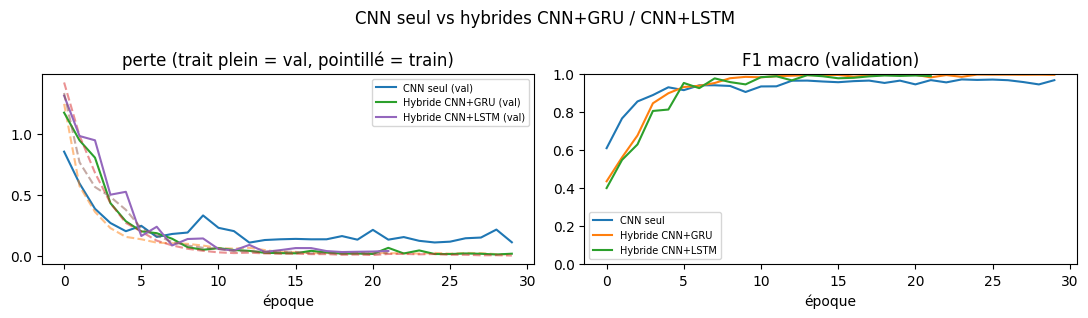

In [15]:
keras.utils.set_random_seed(SEED)
m = construire_hybride("gru"); m.summary()
R4 = entrainer(N_HGRU, m, "brut", "Hybride", EPOCHS["hybride"], suivre_grad=True, patience=PATIENCE["hybride"],
               remarque="tronc CNN (÷16) + GRU(32)")

keras.utils.set_random_seed(SEED)
m = construire_hybride("lstm"); m.summary()
R5 = entrainer(N_HLSTM, m, "brut", "Hybride", EPOCHS["hybride"], patience=PATIENCE["hybride"],
               remarque="tronc CNN (÷16) + LSTM(32) ; comparaison LSTM/GRU")
courbes([N_CNN, N_HGRU, N_HLSTM], "CNN seul vs hybrides CNN+GRU / CNN+LSTM")

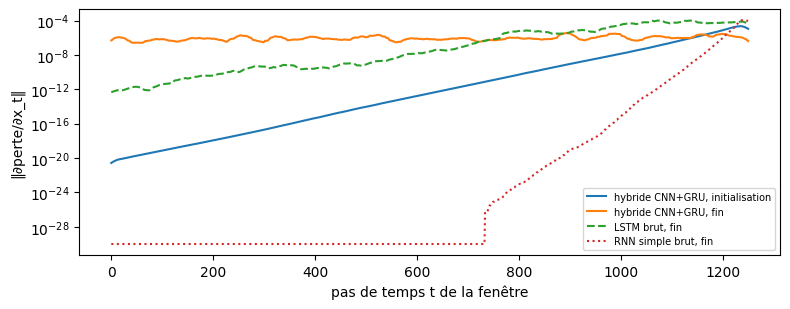

RNN simple (brut)      rapport gradient début(0-99)/fin(1150-1249) = 0.00e+00
LSTM (brut)            rapport gradient début(0-99)/fin(1150-1249) = 2.38e-08
Hybride CNN+GRU        rapport gradient début(0-99)/fin(1150-1249) = 3.38e-01


In [16]:
# ---- Le gradient atteint-il tous les pas de la fenêtre dans l'hybride ? ----
h = MODELES[N_HGRU]["hist"]
plt.figure(figsize=(8, 3.2))
plt.semilogy(lisser(h["gpas_init"]) + 1e-30, label="hybride CNN+GRU, initialisation")
plt.semilogy(lisser(h["gpas_fin"]) + 1e-30, label="hybride CNN+GRU, fin")
plt.semilogy(lisser(MODELES[N_LSTM]["hist"]["gpas_fin"]) + 1e-30, "--", label="LSTM brut, fin")
plt.semilogy(lisser(MODELES[N_SIMPLE]["hist"]["gpas_fin"]) + 1e-30, ":", label="RNN simple brut, fin")
plt.xlabel("pas de temps t de la fenêtre"); plt.ylabel("‖∂perte/∂x_t‖"); plt.legend(fontsize=7); plt.tight_layout(); plt.show()
for n in [N_SIMPLE, N_LSTM, N_HGRU]:
    g = MODELES[n]["hist"]["gpas_fin"]
    print(f"{n:22s} rapport gradient début(0-99)/fin(1150-1249) = {g[:100].mean() / (g[-100:].mean() + 1e-30):.2e}")

## 8. Expérience 3 : la fenêtre comme suite de battements (≤ 40) – GRU avec masquage

Chaque fenêtre devient une suite `(RR, amplitude)` de **au plus 40 pas** (au lieu de 1 250), complétée par des zéros. La couche `Masking(mask_value=0.0)` indique au GRU d'**ignorer le remplissage** (l'état n'est pas mis à jour sur les pas masqués ; la sortie est celle du dernier battement réel).

Remarque de méthode : cette représentation dépend de la **qualité du détecteur de QRS** (battements manqués ou faux positifs sur signal bruité) et ajoute un **prétraitement** au coût d'inférence : il est inclus dans la latence mesurée.

Model: "gru_battements"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ masking (Masking)               │ (None, 40, 2)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_2 (GRU)                     │ (None, 32)             │         3,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,677 (18.27 KB)

 Trainable params: 4,677 (18.27 KB)

 Non-trainable params: 0 (0.00 B)

[GRU battements (masqué)] époque  1/60 | perte 1.242 | perte val 1.096 | F1 macro val 0.456 | 2.2 s
[GRU battements (masqué)] époque  2/60 | perte 0.931 | perte val 0.960 | F1 macro val 0.540 | 0.9 s
[GRU battements (masqué)] époque  3/60 | perte 0.794 | perte val 0.678 | F1 macro val 0.666 | 1.0 s
[GRU battements (masqué)] époque  4/60 | perte 0.642 | perte val 0.575 | F1 macro val 0.695 | 0.9 s
[GRU battements (masqué)] époque  5/60 | perte 0.595 | perte val 0.551 | F1 macro val 0.714 | 0.9 s
[GRU battements (masqué)] époque  6/60 | perte 0.563 | perte val 0.536 | F1 macro val 0.729 | 0.9 s
[GRU battements (masqué)] époque  7/60 | perte 0.531 | perte val 0.519 | F1 macro val 0.746 | 0.9 s
[GRU battements (masqué)] époque  8/60 | perte 0.483 | perte val 0.516 | F1 macro val 0.789 | 0.9 s
[GRU battements (masqué)] époque  9/60 | perte 0.426 | perte val 0.464 | F1 macro val 0.814 | 0.9 s
[GRU battements (masqué)] époque 10/60 | perte 0.388 | perte val 0.416 | F1 macro val 0.827 | 0.9 s


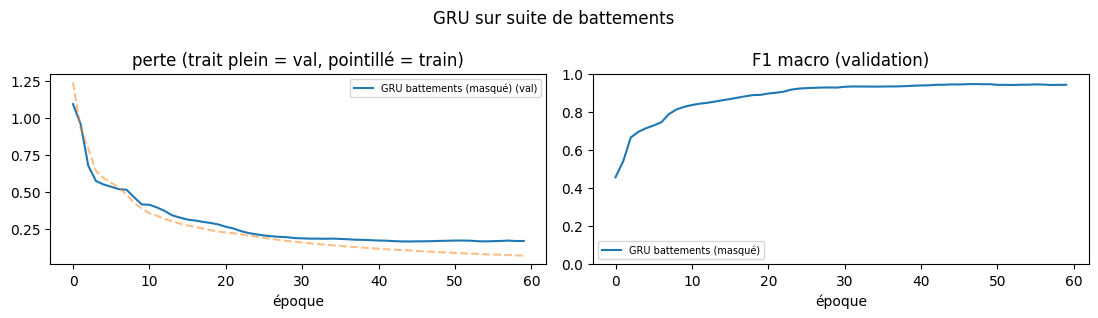

In [17]:
def construire_beats(masque=True, units=32):
    L = [layers.Input((N_BATT, 2))]
    if masque:
        L.append(layers.Masking(mask_value=0.0))
    L += [layers.GRU(units), layers.Dense(32, activation="relu"), layers.Dense(NC, activation="softmax")]
    return keras.Sequential(L, name="gru_battements" + ("" if masque else "_sans_masque"))

keras.utils.set_random_seed(SEED)
m = construire_beats(True); m.summary()
R6 = entrainer(N_BGRU, m, "beats", "Battements", EPOCHS["beats"], patience=PATIENCE["beats"],
               remarque="Masking(0)+GRU(32)+Dense(32) sur 40 x (RR, amp)")

# ---- Essai d'ablation (journalisé) : sans masquage, le remplissage est lu comme de vraies données ----
keras.utils.set_random_seed(SEED)
m = construire_beats(False)
_ = entrainer("GRU battements sans masque (essai)", m, "beats", "Battements", EPOCHS["beats"], patience=PATIENCE["beats"],
              statut="essai", registrer=False, sauver=False,
              remarque="Ablation : même modèle sans Masking ; le GRU doit deviner où s'arrête la suite")
courbes([N_BGRU], "GRU sur suite de battements")

In [18]:
# ---- Ablation du masquage : comparaison sur la validation ----
abl = [r for r in JOURNAL if r["modele"] in (N_BGRU, "GRU battements sans masque (essai)")]
display(pd.DataFrame(abl)[["modele", "statut", "epochs", "f1_macro_val", "sens_fa95_val", "params"]])

,modele,statut,epochs,f1_macro_val,sens_fa95_val,params
0,GRU battements (masqué),référence,60,0.9464,0.9622,4677
1,GRU battements sans masque (essai),essai,60,0.9326,0.9034,4677


## 9. Évaluation, comparaison et analyse (sur la **validation**)

### 9.1 Tableau global et comparaison classe par classe

,famille,paramètres,taille float32 (Mo),fichier .keras (Mo),temps/époque (s),latence/fenêtre (ms),F1 macro val,sens. FA @spec95 val
modèle,,,,,,,,
RNN simple (brut),RNN brut,1253,0.005,0.037,8.1,3110.4,0.2095,0.0378
LSTM (brut),RNN brut,4517,0.017,0.075,4.5,20.9,0.4868,0.1639
CNN seul,CNN,174021,0.664,2.044,2.0,13.3,0.9706,1.0000
Hybride CNN+GRU,Hybride,23653,0.090,0.322,1.4,18.5,0.9961,1.0000
Hybride CNN+LSTM,Hybride,26661,0.102,0.357,1.4,20.0,0.9933,1.0000
GRU battements (masqué),Battements,4677,0.018,0.083,0.9,13.1,0.9464,0.9622


,Sinusal,FA,Extrasyst. V,Tachy sinus.,Bloc AV 2
RNN simple (brut),0.210000,0.108000,0.430000,0.186000,0.114000
LSTM (brut),0.418000,0.420000,0.597000,0.707000,0.293000
CNN seul,0.973000,0.983000,0.953000,0.972000,0.972000
Hybride CNN+GRU,0.996000,0.998000,0.995000,0.997000,0.994000
Hybride CNN+LSTM,0.994000,0.998000,0.997000,0.978000,1.000000
GRU battements (masqué),0.957000,0.889000,0.962000,0.965000,0.959000


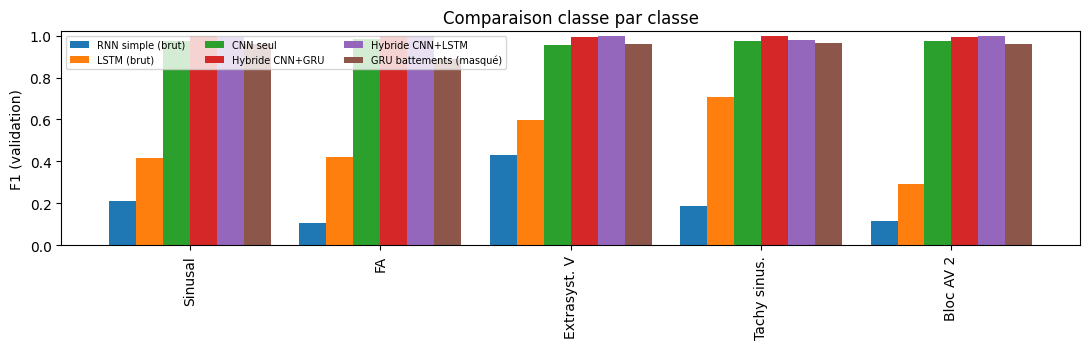

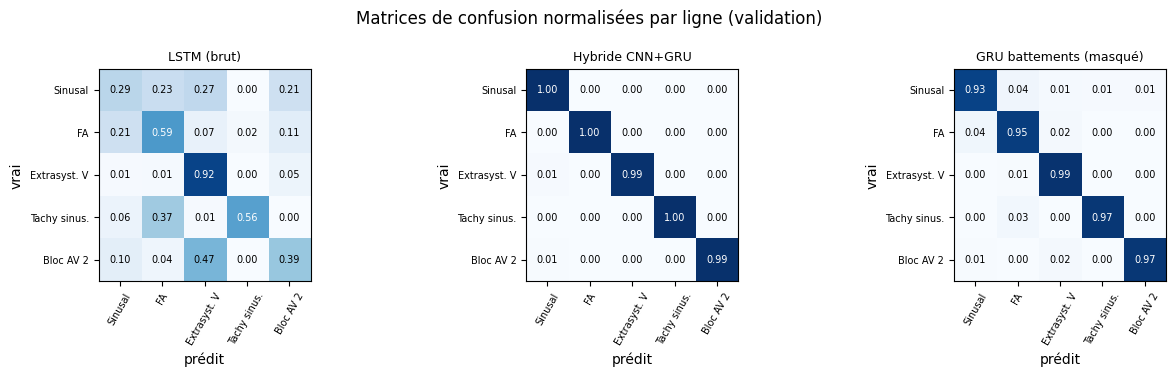

In [19]:
PRINCIPAUX = [N_SIMPLE, N_LSTM, N_CNN, N_HGRU, N_HLSTM, N_BGRU]

def tab_global():
    rows = []
    for n in PRINCIPAUX:
        r = MODELES[n]
        rows.append({"modèle": n, "famille": r["famille"], "paramètres": r["params"],
                     "taille float32 (Mo)": round(r["taille_mo_f32"], 3), "fichier .keras (Mo)": round(r["taille_fichier_mo"], 3),
                     "temps/époque (s)": round(r["t_epoque"], 1), "latence/fenêtre (ms)": round(r["latence_ms"], 1),
                     "F1 macro val": round(r["val"]["f1_macro"], 4), "sens. FA @spec95 val": round(r["val"]["sens_fa95"], 4)})
    return pd.DataFrame(rows).set_index("modèle")

T = tab_global(); display(T)

F1C = pd.DataFrame({n: MODELES[n]["val"]["f1_classes"] for n in PRINCIPAUX}, index=CLASSES).T
display(F1C.round(3).style.background_gradient(cmap="RdYlGn", vmin=0.3, vmax=1.0, axis=None).set_caption("F1 par classe (validation)"))
F1C.T.plot.bar(figsize=(11, 3.6), width=0.85); plt.ylabel("F1 (validation)"); plt.ylim(0, 1.02)
plt.legend(fontsize=7, ncol=3); plt.title("Comparaison classe par classe"); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
for a, n in zip(ax, [N_LSTM, N_HGRU, N_BGRU]):
    cm = MODELES[n]["val"]["cm"]; cmn = cm / cm.sum(1, keepdims=True)
    a.imshow(cmn, vmin=0, vmax=1, cmap="Blues"); a.set_title(n, fontsize=9)
    a.set_xticks(range(NC)); a.set_yticks(range(NC)); a.set_xticklabels(CLASSES, rotation=60, fontsize=7); a.set_yticklabels(CLASSES, fontsize=7)
    for i in range(NC):
        for j in range(NC):
            a.text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center", fontsize=7, color="white" if cmn[i, j] > 0.5 else "black")
    a.set_xlabel("prédit"); a.set_ylabel("vrai")
plt.suptitle("Matrices de confusion normalisées par ligne (validation)"); plt.tight_layout(); plt.show()

In [20]:
# ---- Analyse des erreurs : quelles confusions dominent pour chaque famille ? ----
for n in [N_LSTM, N_HGRU, N_BGRU]:
    cm = MODELES[n]["val"]["cm"].copy(); np.fill_diagonal(cm, 0)
    top = np.dstack(np.unravel_index(np.argsort(-cm.ravel())[:3], cm.shape))[0]
    print(f"{n:26s} principales confusions (vrai -> prédit) :",
          "; ".join(f"{CLASSES[i]} -> {CLASSES[j]} ({cm[i, j]})" for i, j in top))

LSTM (brut)                principales confusions (vrai -> prédit) : Sinusal -> Extrasyst. V (240); Sinusal -> FA (208); Sinusal -> Bloc AV 2 (187)
Hybride CNN+GRU            principales confusions (vrai -> prédit) : Extrasyst. V -> Sinusal (3); Sinusal -> FA (1); Sinusal -> Bloc AV 2 (1)
GRU battements (masqué)    principales confusions (vrai -> prédit) : Sinusal -> FA (35); Sinusal -> Extrasyst. V (11); FA -> Sinusal (9)


### 9.2 Stabilité (3 graines) pour les deux modèles les moins coûteux

Une seule graine ne permet pas de conclure sur un écart de quelques millièmes de F1 : on répète l'entraînement de l'hybride CNN+GRU et du GRU sur battements avec 3 graines (validation uniquement ; ces essais sont journalisés avec `statut="stabilité"` et **ne sont pas** candidats à la sélection).

In [21]:
STAB = {}
if STABILITE:
    for nom, constr, ent, fam, ek in [(N_HGRU, lambda: construire_hybride("gru"), "brut", "Hybride", "hybride"),
                                      (N_BGRU, lambda: construire_beats(True), "beats", "Battements", "beats")]:
        f1s, sens = [], []
        for s in (1, 2, 3):
            keras.utils.set_random_seed(s)
            r = entrainer(f"{nom} [graine {s}]", constr(), ent, fam, EPOCHS[ek], patience=PATIENCE[ek], seed=s,
                          statut="stabilité", registrer=False, sauver=False, remarque="répétition de graine")
            f1s.append(r["val"]["f1_macro"]); sens.append(r["val"]["sens_fa95"])
        STAB[nom] = (np.mean(f1s), np.std(f1s), np.mean(sens), np.std(sens))
    display(pd.DataFrame(STAB, index=["F1 macro moy.", "F1 macro écart-type", "sens. FA moy.", "sens. FA écart-type"]).T.round(4))
else:
    print("STABILITE = False : étape sautée")

[Hybride CNN+GRU [graine 1]] époque  1/30 | perte 1.338 | perte val 1.279 | F1 macro val 0.411 | 4.6 s
[Hybride CNN+GRU [graine 1]] époque  2/30 | perte 0.841 | perte val 0.803 | F1 macro val 0.681 | 2.7 s
[Hybride CNN+GRU [graine 1]] époque  3/30 | perte 0.589 | perte val 0.716 | F1 macro val 0.693 | 1.4 s
[Hybride CNN+GRU [graine 1]] époque  4/30 | perte 0.454 | perte val 0.509 | F1 macro val 0.793 | 1.4 s
[Hybride CNN+GRU [graine 1]] époque  5/30 | perte 0.280 | perte val 0.229 | F1 macro val 0.923 | 1.4 s
[Hybride CNN+GRU [graine 1]] époque  6/30 | perte 0.152 | perte val 0.147 | F1 macro val 0.953 | 1.4 s
[Hybride CNN+GRU [graine 1]] époque  7/30 | perte 0.106 | perte val 0.104 | F1 macro val 0.963 | 1.4 s
[Hybride CNN+GRU [graine 1]] époque  8/30 | perte 0.061 | perte val 0.091 | F1 macro val 0.974 | 1.4 s
[Hybride CNN+GRU [graine 1]] époque  9/30 | perte 0.041 | perte val 0.076 | F1 macro val 0.976 | 1.4 s
[Hybride CNN+GRU [graine 1]] époque 10/30 | perte 0.039 | perte val 0.096

,F1 macro moy.,F1 macro écart-type,sens. FA moy.,sens. FA écart-type
Hybride CNN+GRU,0.9923,0.0055,1.0000,0.0000
GRU battements (masqué),0.9415,0.0133,0.9552,0.0139


### 9.3 Coût d'entraînement des trois familles et conclusion pour l'embarqué

,paramètres,taille float32 (Mo),temps/époque (s),latence/fenêtre (ms),F1 macro val,temps total ≈ (s)
modèle,,,,,,
RNN simple (brut),1253,0.005,8.1,3110.4,0.2095,98
LSTM (brut),4517,0.017,4.5,20.9,0.4868,68
CNN seul,174021,0.664,2.0,13.3,0.9706,59
Hybride CNN+GRU,23653,0.090,1.4,18.5,0.9961,42
Hybride CNN+LSTM,26661,0.102,1.4,20.0,0.9933,32
GRU battements (masqué),4677,0.018,0.9,13.1,0.9464,55


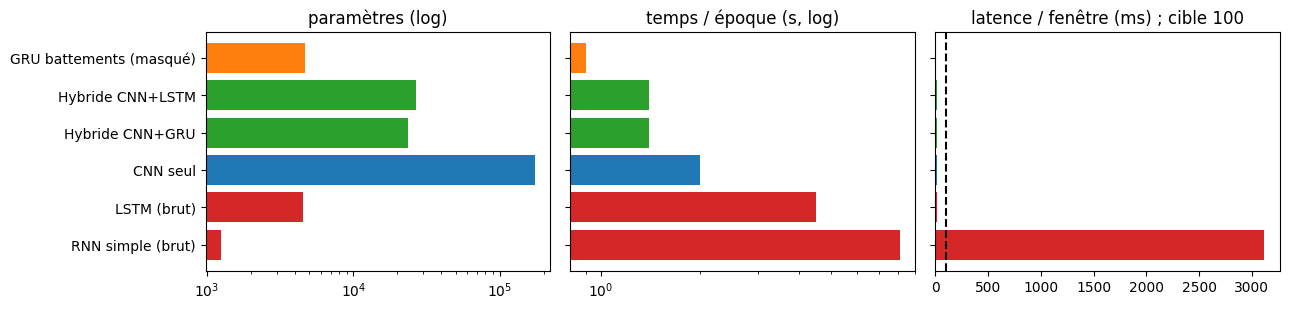

Respectent taille ≤ 2 Mo : ['RNN simple (brut)', 'LSTM (brut)', 'CNN seul', 'Hybride CNN+GRU', 'Hybride CNN+LSTM', 'GRU battements (masqué)']
Respectent latence ≤ 100 ms (sur CE matériel) : ['LSTM (brut)', 'CNN seul', 'Hybride CNN+GRU', 'Hybride CNN+LSTM', 'GRU battements (masqué)']
Rapport temps/époque RNN brut / hybride : 5.8 | RNN brut / battements : 9.0


In [22]:
C = T[["paramètres", "taille float32 (Mo)", "temps/époque (s)", "latence/fenêtre (ms)", "F1 macro val"]].copy()
C["temps total ≈ (s)"] = [round(MODELES[n]["t_epoque"] * MODELES[n]["epochs_faites"]) for n in C.index]
display(C)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
couleurs = ["tab:red", "tab:red", "tab:blue", "tab:green", "tab:green", "tab:orange"]
ax[0].barh(C.index, C["paramètres"], color=couleurs); ax[0].set_xscale("log"); ax[0].set_title("paramètres (log)")
ax[1].barh(C.index, C["temps/époque (s)"], color=couleurs); ax[1].set_xscale("log"); ax[1].set_title("temps / époque (s, log)")
ax[2].barh(C.index, C["latence/fenêtre (ms)"], color=couleurs); ax[2].axvline(100, color="k", ls="--"); ax[2].set_title("latence / fenêtre (ms) ; cible 100")
for a in ax[1:]:
    a.set_yticklabels([])
plt.tight_layout(); plt.show()

# Diagnostic automatique pour la conclusion
ok_taille = C["taille float32 (Mo)"] <= 2
ok_lat = C["latence/fenêtre (ms)"] <= 100
print("Respectent taille ≤ 2 Mo :", list(C.index[ok_taille]))
print("Respectent latence ≤ 100 ms (sur CE matériel) :", list(C.index[ok_lat]))
print("Rapport temps/époque RNN brut / hybride :", round(C.loc[N_SIMPLE, "temps/époque (s)"] / C.loc[N_HGRU, "temps/époque (s)"], 1),
      "| RNN brut / battements :", round(C.loc[N_SIMPLE, "temps/époque (s)"] / C.loc[N_BGRU, "temps/époque (s)"], 1))

**Conclusion pour l'usage embarqué (valeurs mesurées).**

* **Taille** : toutes les tailles `float32` sont très inférieures à 2 Mo (de 0,005 Mo pour le RNN simple à 0,66 Mo pour le CNN seul). Attention : le fichier `.keras` du CNN seul pèse **2,04 Mo** car il contient aussi l'état de l'optimiseur Adam ; les poids seuls n'en font que 0,66. Cette contrainte ne discrimine donc presque pas ; elle pénalise seulement le `Flatten→Dense` du CNN (174 021 paramètres, 7× plus que l'hybride).
* **Temps d'entraînement par époque** : RNN simple 8,1 s, LSTM brut 4,5 s, CNN seul 2,0 s, hybrides 1,4 s, GRU sur battements 0,9 s. Le RNN simple coûte **5,8 fois** l'hybride et **9 fois** le GRU sur battements, alors qu'il a le moins de paramètres (1 253) : le nombre de paramètres ne mesure pas le coût, il faut le multiplier par la longueur de la séquence (1 250 pas contre 78 pour l'hybride et ≤ 40 pour les battements).
* **Latence par fenêtre** (batch 1, GPU Colab) : 13,1 ms (battements, détection QRS incluse), 13,3 ms (CNN), 18,5 ms (hybride GRU), 20,0 ms (hybride LSTM), 20,9 ms (LSTM brut), 3 110 ms (RNN simple, artefact de l'absence de noyau cuDNN). Tous sauf le RNN simple sont sous 100 ms *sur ce matériel* ; à reverifier sur la cible réelle (TFLite).
* **Choix** : l'hybride CNN+GRU (23 653 paramètres, 0,09 Mo, 18,5 ms, F1 macro validation 0,996) est le meilleur compromis. Le GRU sur battements est le plus léger (4 677 paramètres, 0,018 Mo) mais plafonne à un F1 de 0,946 (0,941 ± 0,013 sur 3 graines), sous la cible de 0,97, et dépend du détecteur de QRS.

## 10. Sélection du modèle (validation) puis **test, une seule fois**

Règle de sélection fixée **avant** de regarder le test : parmi les modèles principaux respectant **taille ≤ 2 Mo**, on prend celui qui a le **F1 macro de validation le plus élevé** ; en cas d'écart < 0,005, on choisit la plus faible latence.

In [23]:
cand = T[T["taille float32 (Mo)"] <= 2].sort_values("F1 macro val", ascending=False)
best_f1 = cand["F1 macro val"].iloc[0]
proches = cand[cand["F1 macro val"] >= best_f1 - 0.005].sort_values("latence/fenêtre (ms)")
CHOIX = proches.index[0]
print("Candidats à moins de 0,005 du meilleur F1 :", list(proches.index))
print("==> MODÈLE RETENU :", CHOIX)
journal_exp(modele=CHOIX, famille=MODELES[CHOIX]["famille"], entree=MODELES[CHOIX]["entree"], statut="retenu",
            f1_macro_val=round(MODELES[CHOIX]["val"]["f1_macro"], 4), remarque="sélection sur validation (règle F1 puis latence)")

Candidats à moins de 0,005 du meilleur F1 : ['Hybride CNN+GRU', 'Hybride CNN+LSTM']
==> MODÈLE RETENU : Hybride CNN+GRU


Modèle : Hybride CNN+GRU
F1 macro test = 0.9972 | exactitude = 0.9972
Sensibilité FA à spécificité 95 % (courbe ROC test) = 1.0000 (spécificité réelle 1.000)
Avec le seuil FA fixé sur la validation : sensibilité = 0.9929, spécificité = 1.0000


,F1,rappel
Sinusal,0.997,0.998
FA,0.998,0.996
Extrasyst. V,0.998,1.000
Tachy sinus.,0.997,1.000
Bloc AV 2,0.997,0.993


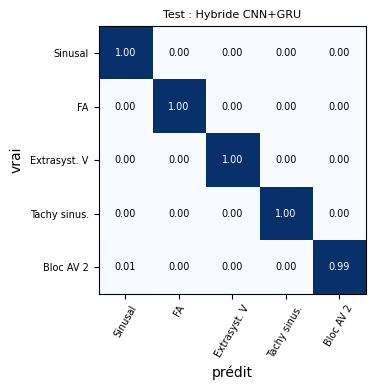

,cible,mesuré,atteint,écart
0,"F1 macro ≥ 0,97",0.9972,True,0.0272
1,"sens. FA @ spec 95 % ≥ 0,95",1.0000,True,0.0500
2,taille ≤ 2 Mo,0.0900,True,-1.9100
3,latence ≤ 100 ms,18.5000,True,-81.5000


In [24]:
# ======= TEST : cellule à exécuter UNE SEULE FOIS =======
if "TEST_UTILISE" in globals():
    raise RuntimeError("Le test a déjà été utilisé dans cette session : on ne le rejoue pas (protocole).")
TEST_UTILISE = True

r = MODELES[CHOIX]
Xte, yte = DATA[r["entree"]]["test"], Y["test"]
pt = r["model"].predict(Xte, batch_size=256, verbose=0)
et = evaluer(pt, yte)
# Seuil FA fixé sur la VALIDATION puis appliqué au test
s_fa = r["val"]["seuil_fa"]
yb = (yte == 1)
sens_seuil_val = float((pt[yb, 1] >= s_fa).mean()); spec_seuil_val = float((pt[~yb, 1] < s_fa).mean())

print(f"Modèle : {CHOIX}")
print(f"F1 macro test = {et['f1_macro']:.4f} | exactitude = {et['acc']:.4f}")
print(f"Sensibilité FA à spécificité 95 % (courbe ROC test) = {et['sens_fa95']:.4f} (spécificité réelle {et['spec_fa']:.3f})")
print(f"Avec le seuil FA fixé sur la validation : sensibilité = {sens_seuil_val:.4f}, spécificité = {spec_seuil_val:.4f}")
display(pd.DataFrame({"F1": et["f1_classes"], "rappel": et["rappel_classes"]}, index=CLASSES).round(3))

cm = et["cm"]; cmn = cm / cm.sum(1, keepdims=True)
plt.figure(figsize=(4.6, 4)); plt.imshow(cmn, vmin=0, vmax=1, cmap="Blues")
plt.xticks(range(NC), CLASSES, rotation=60, fontsize=7); plt.yticks(range(NC), CLASSES, fontsize=7)
for i in range(NC):
    for j in range(NC):
        plt.text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center", fontsize=7, color="white" if cmn[i, j] > 0.5 else "black")
plt.title(f"Test : {CHOIX}", fontsize=8); plt.xlabel("prédit"); plt.ylabel("vrai"); plt.tight_layout(); plt.show()

CIBLES = pd.DataFrame({
    "cible": ["F1 macro ≥ 0,97", "sens. FA @ spec 95 % ≥ 0,95", "taille ≤ 2 Mo", "latence ≤ 100 ms"],
    "mesuré": [round(et["f1_macro"], 4), round(et["sens_fa95"], 4), round(r["taille_mo_f32"], 3), round(r["latence_ms"], 1)],
    "atteint": [et["f1_macro"] >= 0.97, et["sens_fa95"] >= 0.95, r["taille_mo_f32"] <= 2, r["latence_ms"] <= 100],
    "écart": [round(et["f1_macro"] - 0.97, 4), round(et["sens_fa95"] - 0.95, 4), round(r["taille_mo_f32"] - 2, 3), round(r["latence_ms"] - 100, 1)]})
display(CIBLES)
journal_exp(modele=CHOIX, famille=r["famille"], entree=r["entree"], statut="test (unique)", f1_macro_test=round(et["f1_macro"], 4),
            sens_fa95_test=round(et["sens_fa95"], 4), remarque="évaluation finale du jalon 4, une seule fois")

## 11. Page de décisions

### 11.1 Tableau des résultats

In [25]:
final = T.copy()
final.insert(0, "statut", ["retenu" if n == CHOIX else "comparé" for n in final.index])
display(final)
display(Markdown(f"**Modèle retenu : {CHOIX}** — F1 macro val = {MODELES[CHOIX]['val']['f1_macro']:.3f}, "
                 f"F1 macro **test** = {et['f1_macro']:.3f}, sensibilité FA@spec95 test = {et['sens_fa95']:.3f}, "
                 f"{MODELES[CHOIX]['params']:,} paramètres, {MODELES[CHOIX]['latence_ms']:.1f} ms/fenêtre."))
if STAB:
    for n, (mf, sf, ms_, ss_) in STAB.items():
        display(Markdown(f"Stabilité 3 graines — {n} : F1 macro val = {mf:.3f} ± {sf:.3f} ; sens. FA = {ms_:.3f} ± {ss_:.3f}"))

# Phrases générées à partir des mesures (pour rédiger la page, à reformuler)
fs, fl, fh, fb = [MODELES[n]["val"]["f1_macro"] for n in [N_SIMPLE, N_LSTM, N_HGRU, N_BGRU]]
fc = MODELES[N_CNN]["val"]["f1_macro"]
print(f"- RNN simple brut : F1 val {fs:.3f} ; LSTM brut : {fl:.3f} ; CNN seul : {fc:.3f} ; hybride CNN+GRU : {fh:.3f} ; GRU battements : {fb:.3f}.")
print(f"- Gain de l'hybride sur le LSTM brut : {fh - fl:+.3f} de F1 ; sur le CNN seul : {fh - fc:+.3f}.")
pire = pd.Series(MODELES[N_LSTM]['val']['f1_classes'], index=CLASSES).idxmin()
print(f"- Classe la plus difficile pour le LSTM brut : {pire} (F1 {MODELES[N_LSTM]['val']['f1_classes'].min():.3f}).")

,statut,famille,paramètres,taille float32 (Mo),fichier .keras (Mo),temps/époque (s),latence/fenêtre (ms),F1 macro val,sens. FA @spec95 val
modèle,,,,,,,,,
RNN simple (brut),comparé,RNN brut,1253,0.005,0.037,8.1,3110.4,0.2095,0.0378
LSTM (brut),comparé,RNN brut,4517,0.017,0.075,4.5,20.9,0.4868,0.1639
CNN seul,comparé,CNN,174021,0.664,2.044,2.0,13.3,0.9706,1.0000
Hybride CNN+GRU,retenu,Hybride,23653,0.090,0.322,1.4,18.5,0.9961,1.0000
Hybride CNN+LSTM,comparé,Hybride,26661,0.102,0.357,1.4,20.0,0.9933,1.0000
GRU battements (masqué),comparé,Battements,4677,0.018,0.083,0.9,13.1,0.9464,0.9622


**Modèle retenu : Hybride CNN+GRU** — F1 macro val = 0.996, F1 macro **test** = 0.997, sensibilité FA@spec95 test = 1.000, 23,653 paramètres, 18.5 ms/fenêtre.

Stabilité 3 graines — Hybride CNN+GRU : F1 macro val = 0.992 ± 0.006 ; sens. FA = 1.000 ± 0.000

Stabilité 3 graines — GRU battements (masqué) : F1 macro val = 0.941 ± 0.013 ; sens. FA = 0.955 ± 0.014

- RNN simple brut : F1 val 0.210 ; LSTM brut : 0.487 ; CNN seul : 0.971 ; hybride CNN+GRU : 0.996 ; GRU battements : 0.946.
- Gain de l'hybride sur le LSTM brut : +0.509 de F1 ; sur le CNN seul : +0.026.
- Classe la plus difficile pour le LSTM brut : Bloc AV 2 (F1 0.293).


### 11.2 Choix retenus et justifications

**Synthèse chiffrée (validation, graine 42 ; test uniquement pour le modèle retenu).**

| Modèle | Paramètres | s/époque | Latence (ms) | F1 macro val | Sens. FA @ spec 95 % val |
|---|---|---|---|---|---|
| RNN simple (brut) | 1 253 | 8,1 | 3 110 | 0,210 | 0,038 |
| LSTM (brut) | 4 517 | 4,5 | 20,9 | 0,487 | 0,164 |
| CNN seul | 174 021 | 2,0 | 13,3 | 0,971 | 1,000 |
| **Hybride CNN+GRU (retenu)** | 23 653 | 1,4 | 18,5 | **0,996** | 1,000 |
| Hybride CNN+LSTM | 26 661 | 1,4 | 20,0 | 0,993 | 1,000 |
| GRU sur battements (masqué) | 4 677 | 0,9 | 13,1 | 0,946 | 0,962 |

**Modèle retenu : hybride CNN+GRU.** Règle fixée avant le test (meilleur F1 de validation parmi les modèles ≤ 2 Mo, puis plus faible latence si l'écart est < 0,005) : le GRU et le LSTM hybrides sont à 0,003 l'un de l'autre, le GRU est choisi pour sa latence (18,5 contre 20,0 ms) et ses paramètres (23 653 contre 26 661). **Cet écart est inférieur à la variabilité entre graines** (hybride GRU : 0,998 / 0,994 / 0,985 pour les graines 1, 2, 3 ; moyenne 0,992 ± 0,006) : le choix GRU contre LSTM est donc un choix de coût, pas une supériorité démontrée. **Résultat test (une seule évaluation) : F1 macro 0,9972, exactitude 0,9972, sensibilité FA à spécificité 95 % = 1,000** (0,993 avec le seuil FA fixé sur la validation, spécificité 1,000), soit environ 5 fenêtres mal classées sur 1 800.

**Pourquoi le modèle hybride réussit là où le RNN sur le signal brut échoue.**
1. **Longueur de la séquence et gradient (observé).** Le RNN simple lit 1 250 pas : le gradient des 100 premiers pas est exactement nul et le F1 reste au niveau du hasard (0,21) ; le LSTM brut atteint 0,49 avec un rapport de gradient début/fin de 2×10⁻⁸. Dans l'hybride, les 1 250 points sont ramenés à **78 pas** (÷ 16) : le rapport début/fin du gradient d'entrée vaut **0,34** (contre 2×10⁻⁸ et 0), c'est-à-dire que la perte est sensible à toute la fenêtre. C'est exactement le mécanisme du § 5.1 (0,9¹²⁵⁰ ≈ 6×10⁻⁵⁸).
2. **Niveau d'abstraction.** Un point isolé de l'ECG n'a presque aucun sens diagnostique ; le CNN le transforme en descripteurs locaux (pente, pic QRS, bruit), que le GRU combine ensuite en succession (irrégularité des RR en FA, prématurité des extrasystoles, pauses du bloc AV).
3. **Apport du récurrent par rapport au CNN seul (même tronc).** F1 macro de validation 0,996 contre 0,971 (+0,025) et surtout une meilleure homogénéité par classe : le F1 du CNN seul varie de 0,953 (extrasystoles) à 0,983 (FA), celui de l'hybride reste entre 0,994 et 0,998, avec 7 fois moins de paramètres (23 653 contre 174 021).
4. **Réserve honnête.** Le RNN brut est évalué sous un budget de 12-15 époques et une seule graine ; la courbe du LSTM monte encore à la fin. On peut affirmer qu'il est très loin de l'hybride à budget égal, pas qu'il ne pourrait jamais y arriver.

**Choix de la représentation d'entrée.**
* *Signal brut (via l'hybride)* : meilleure performance (F1 0,996), apprend la morphologie du QRS ; coût un peu plus élevé (18,5 ms) mais acceptable.
* *Suite de battements (GRU masqué)* : 4 677 paramètres, 0,9 s/époque, séquence 30 fois plus courte, mais F1 de validation 0,946 (0,941 ± 0,013 sur 3 graines) et la FA est la classe la plus faible (F1 0,889 ; 35 fenêtres sinusales prédites FA sur la validation). Explication la plus probable (non testée) : erreurs du détecteur de QRS (battements manqués ou faux) qui fabriquent de l'irrégularité, et perte de la morphologie fine (onde P). 
* *Ablation du masquage* : sans `Masking`, F1 de validation 0,933 contre 0,946 et sensibilité FA 0,903 contre 0,962. Avec un seul entraînement par variante, l'écart de F1 (0,013) est du même ordre que la variabilité entre graines (0,013) ; l'écart de sensibilité FA (0,059) est plus net mais reste à confirmer sur plusieurs graines.
* **Décision** : signal brut avec CNN+GRU. La représentation en battements reste une piste légère si le coût d'inférence devient déterminant, à condition d'améliorer la détection de QRS.

**Écart aux cibles (système final).**

| Cible | Mesuré (test) | Atteint |
|---|---|---|
| F1 macro ≥ 0,97 | 0,9972 | oui (+0,027) |
| Sensibilité FA à spécificité 95 % ≥ 0,95 | 1,000 | oui (+0,050) |
| Taille ≤ 2 Mo | 0,090 Mo (0,32 Mo en fichier `.keras` avec optimiseur) | oui |
| Latence ≤ 100 ms | 18,5 ms | oui |

Toutes les cibles de ce jalon sont atteintes, mais il faut les relativiser : (i) les signaux sont **simulés** et uniquement du **Holter A** : le test suit la même distribution que l'entraînement, le domaine du patch (amplitude plus faible, autre morphologie, bruit) n'est pas évalué ici et fait l'objet du jalon 3 ; (ii) la sensibilité FA est **saturée à 1,000** pour le CNN et les deux hybrides : cette métrique ne les départage pas ; (iii) avec 1 800 fenêtres de test, une fenêtre pèse 0,06 point d'exactitude : 0,9972 correspond à environ 5 erreurs, l'incertitude est de l'ordre de quelques dixièmes de point ; (iv) la latence est mesurée sur GPU T4 avec Keras (batch 1), pas sur la cible embarquée, et ne compte pas le prétraitement de normalisation ; (v) pas de réglage fin des hyperparamètres, une architecture par famille, un seul budget d'entraînement.

**Pistes d'amélioration.** GRU bidirectionnel ; fusion des deux représentations (CNN+GRU sur le signal et battements) ; amélioration du détecteur de QRS ; augmentation de données (bruit, amplitude) pour le patch ; quantification et conversion TFLite avant toute affirmation sur l'embarqué ; plusieurs graines et intervalles de confiance sur le test pour la synthèse finale.

### 11.3 Réponses aux vérifications théoriques
Voir § 5 (vérifiées par le code) : (1) 0,9¹²⁵⁰ ≈ 6,4×10⁻⁵⁸ et 0,99¹²⁵⁰ ≈ 3,5×10⁻⁶ ; le plus petit `float32` normal est franchi après 829 pas avec 0,9 ; un RNN simple sur 1 250 pas ne relie que des événements proches, ce que confirme le gradient nul des 100 premiers pas et le F1 de 0,21 ; (2) LSTM(32) avec 1 variable par pas : 4(32×33+32) = **4 352** paramètres, égal au `count_params()` de Keras (GRU : 3 360 ; SimpleRNN : 1 088).

## 12. Journal d'expériences, sauvegarde et reproductibilité

In [26]:
J = pd.DataFrame(JOURNAL)
display(J[["horodatage", "modele", "famille", "statut", "epochs", "lr", "seed", "params", "t_epoque_s", "latence_ms",
           "f1_macro_val", "sens_fa95_val", "f1_macro_test", "remarque"]].fillna(""))
J.to_csv("journal_experiences_jalon4.csv", index=False)
print("journal enregistré :", os.path.abspath("journal_experiences_jalon4.csv"))
print("modèles sauvegardés :", sorted(os.listdir("modeles")))

# Dépendances effectives
paquets = ["tensorflow", "keras", "numpy", "pandas", "scikit-learn", "scipy", "matplotlib"]
versions = {p: imd.version(p) for p in paquets if p in {d.metadata["Name"].lower() for d in imd.distributions()}}
with open("requirements_jalon4.txt", "w") as f:
    f.write("\n".join(f"{p}=={v}" for p, v in versions.items()) + "\n")
print(versions)

with open("README_jalon4.md", "w", encoding="utf-8") as f:
    f.write(f"""# UC3 - Jalon 4 : Le rythme est une séquence
Procédure : (1) placer uc3_holterA.npz dans data/ ; (2) exécuter uc3_demarrage.ipynb en entier (optionnel : le notebook
inclut des versions de remplacement) ; (3) exécuter ce notebook du début à la fin (MODE_RAPIDE=False) ; graine = {SEED}.
Dépendances : voir requirements_jalon4.txt. Sorties : modeles/*.keras, journal_experiences_jalon4.csv.
Matériel : GPU = {[g.name for g in gpus] if gpus else 'aucun'}.
""")

,horodatage,modele,famille,statut,epochs,lr,seed,params,t_epoque_s,latence_ms,f1_macro_val,sens_fa95_val,f1_macro_test,remarque
0,2026-10-26 11:08:54,RNN simple (brut),RNN brut,référence,12.0,0.001,42.0,1253.0,8.15,3110.36,0.2095,0.0378,,"SimpleRNN(32) sur 1250 pas, référence"
1,2026-10-26 11:10:24,LSTM (brut),RNN brut,référence,15.0,0.001,42.0,4517.0,4.54,20.9,0.4868,0.1639,,"LSTM(32) sur 1250 pas, référence"
2,2026-10-26 11:12:56,RNN simple lr=1e-2 (essai),RNN brut,essai,6.0,0.01,42.0,1253.0,8.09,3105.91,0.1095,0.0756,,Essai : lr x10 pour compenser la lenteur d'app...
3,2026-10-26 11:14:15,CNN seul,CNN,référence,30.0,0.001,42.0,174021.0,1.96,13.29,0.9706,1.0,,"même tronc convolutif que l'hybride, Flatten+D..."
4,2026-10-26 11:15:09,Hybride CNN+GRU,Hybride,référence,30.0,0.001,42.0,23653.0,1.4,18.53,0.9961,1.0,,tronc CNN (÷16) + GRU(32)
5,2026-10-26 11:15:47,Hybride CNN+LSTM,Hybride,référence,22.0,0.001,42.0,26661.0,1.44,19.99,0.9933,1.0,,tronc CNN (÷16) + LSTM(32) ; comparaison LSTM/GRU
6,2026-10-26 11:16:52,GRU battements (masqué),Battements,référence,60.0,0.001,42.0,4677.0,0.92,13.14,0.9464,0.9622,,"Masking(0)+GRU(32)+Dense(32) sur 40 x (RR, amp)"
7,2026-10-26 11:17:55,GRU battements sans masque (essai),Battements,essai,60.0,0.001,42.0,4677.0,0.89,11.66,0.9326,0.9034,,Ablation : même modèle sans Masking ; le GRU d...
8,2026-10-26 11:18:49,Hybride CNN+GRU [graine 1],Hybride,stabilité,30.0,0.001,1.0,23653.0,1.41,18.48,0.998,1.0,,répétition de graine
9,2026-10-26 11:19:25,Hybride CNN+GRU [graine 2],Hybride,stabilité,21.0,0.001,2.0,23653.0,1.4,18.5,0.9942,1.0,,répétition de graine


journal enregistré : /content/journal_experiences_jalon4.csv
modèles sauvegardés : ['CNN_seul.keras', 'GRU_battements_(masqué).keras', 'Hybride_CNN+GRU.keras', 'Hybride_CNN+LSTM.keras', 'LSTM_(brut).keras', 'RNN_simple_(brut).keras']
{'tensorflow': '2.21.0', 'keras': '3.13.2', 'numpy': '2.1.3', 'pandas': '2.2.3', 'scikit-learn': '1.6.1', 'scipy': '1.16.3', 'matplotlib': '3.10.0'}


### Procédure de lancement (README)
1. Placer `uc3_holterA.npz` dans `data/` (ou à côté du notebook) ; Google Colab avec GPU recommandé.
2. *(Optionnel)* exécuter `uc3_demarrage.ipynb` en entier : ses objets (`A`, `detecter_qrs`, `journaliser`, …) sont alors réutilisés ; sinon des versions de remplacement sont définies dans ce notebook.
3. Exécuter ce notebook **du début à la fin** (`MODE_RAPIDE = False`). `MODE_RAPIDE = True` permet un test de fumée de quelques minutes.
4. Fichiers produits : `modeles/*.keras`, `journal_experiences_jalon4.csv`, `requirements_jalon4.txt`, `README_jalon4.md`.

Avant la séance du **27/10/2026 à 14h00** : notebook exécuté (sorties visibles), copie locale des fichiers, journal à jour (essais infructueux inclus).